# Main Analysis

This notebook contains the main analyses of the MW Story experiment:

1. Is story **preference** (interest) related to mind wandering (MW)?
2. Is **semantic decoupling** (distance between thought reports and the story) related to MW?
3. Does preference **moderate** the relation between semantic decoupling and MW?
4. Do these effects replicate with **attention ratings** from thought-content coding?

## Data loading and preprocessing


In [31]:
import os, ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from analysisFunctions import plot_continous_results, linearModelChecks, plotTrialTrack

# Paths
workingDir      = os.getcwd()
dataFolder      = os.path.join(workingDir, "RawData")
analysisName    = "Main_Analysis"
dataQualityPath = os.path.join(workingDir, 'dataQualityChecks')
resultsPath     = os.path.join(workingDir, 'Results', analysisName)
os.makedirs(resultsPath, exist_ok=True)

# Parameters
params = {}
params['OccularTrialRemoval']    = 0
params['MissingDataThresh']      = 0.1
params['BlinkRateThresh']        = 2
params['SaccRateThresh']         = 5
params['StoryLemmaTrialRemocal'] = 5

# Remove story subj: ['AGSZ0905','ALRU1905','BAZA2906','EMBA0605','MAPR0905','MIGO1306','NEST1106','PASZ2505','SERE0605','WOJA1106']
# Remove MW subj:    'MIGO1306'
# TODO: 'MAMPO1405' does not exist in the data – MAPO1405 or MAPO1306?
params['subjectsToRemove'] = ['AGSZ0905','ALRU1905','BAZA2906','EMBA0605','MAPR0905','MIGO1306',
                              'NEST1106','PASZ2505','SERE0605','WOJA1106','MAWA1105','MAMPO1405']

analysisSubName = (f"Analysis_{len(params['subjectsToRemove'])}subjRemoved"
                   f"_OR{params['OccularTrialRemoval']}_SR{params['StoryLemmaTrialRemocal']}")

# Load data
df_Analysis = pd.read_excel(os.path.join(dataFolder, 'storyAnalysis_lags_Filtered_Experience.xlsx'), index_col=0)

# Log + result containers
log_file = open(os.path.join(resultsPath, "finalStatLog_Behav.txt"), 'w+')
coefs,  zvals,  pvals,  conf1,  conf2  = [], [], [], [], []   # main effect
coefsT, zvalsT, pvalsT, conf1T, conf2T = [], [], [], [], []   # time-on-task effect
analysis, subAnalysis = [], []


### This function reduces redundant Adding of resutls to the log and result containers. It takes a fitted model, the name of the main effect, an analysis label, a sub-label, and optionally the name of the time-on-task effect (defaulting to 'trialNum'). It extracts the coefficients, z-values, p-values, and confidence intervals for both the main effect and the time-on-task effect, appending them to their respective lists. It also logs the model's formula and results to a log file.
def add_result(m, main, analysisLabel, subLabel, time='trialNum'):
    """Store the `main` effect and the time-on-task effect by PARAMETER NAME (not position)
    in the results table and the log. The log entry uses the model's own formula."""
    ci = m.conf_int()
    for name, store in [(main, (coefs, zvals, pvals, conf1, conf2)),
                        (time, (coefsT, zvalsT, pvalsT, conf1T, conf2T))]:
        vals = [m.params[name], m.tvalues[name], m.pvalues[name], ci.loc[name, 0], ci.loc[name, 1]]
        for lst, val in zip(store, vals):
            lst.append(val)
    analysis.append(analysisLabel); subAnalysis.append(subLabel)

    conv = getattr(m, 'converged', True)
    log_file.write(f"\n[{analysisLabel} | {subLabel}]  {m.model.formula}"
                   + ("" if conv else "   !!! NOT CONVERGED") + "\n")
    for name in [main, time]:
        log_file.write(f"      {name:38s} Coef: {m.params[name]:7.3f} | z: {m.tvalues[name]:7.3f} "
                       f"| p: {m.pvalues[name]:.4f} | CI: [{ci.loc[name,0]:.3f}, {ci.loc[name,1]:.3f}]\n")

In [2]:
df_Analysis

,Subject,fragment,hasError_x,hasError_y,Utterance,utteranceLength,Sentences,Is_semantic_ref,Is_experiment_ref,Is_Introceptive,...,semDecoupling_WMD_p2,semDecoupling_WMD_p1,semDecoupling_WMD_n1,semDecoupling_WMD_n2,semDecoupling_WMD_n3,semDecoupling_WMD_n4,semDecoupling_BERT_whole,semDecoupling_W2V_whole,semDecoupling_WMD_whole,Attention
Unnamed: 0_x,,,,,,,,,,,,,,,,,,,,,
2,ALRU1905,KAROLINA_1,False,False,"Tak słucham, w tej historii to raczej wyobraża...",268,"['Tak słucham, w tej historii to raczej wyobra...",1,0,0,...,NaN,NaN,1.130183,1.108579,1.095717,1.144764,0.387489,0.849776,1.109283,2
40,ANWI0905,JANEK_1,False,False,"Myślałam o Janku, który chciał pracować i o ic...",152,"['Myślałam o Janku, który chciał pracować i o ...",0,0,0,...,NaN,1.089692,1.074000,1.051910,1.125026,1.096556,0.571478,0.786696,1.076105,2
41,ANWI0905,JANEK_2,False,False,"Myślałam o tych salonach, o których była mowa,...",189,"['Myślałam o tych salonach, o których była mow...",0,0,0,...,1.060670,1.071719,1.041108,1.060761,0.997292,1.001836,0.602820,0.872950,1.042225,1
42,ANWI0905,KAROLINA_1,False,False,"To jak usłyszałam imię Karolina, to wyobraziła...",234,"['To jak usłyszałam imię Karolina, to wyobrazi...",0,0,0,...,NaN,NaN,1.118951,1.082390,1.112494,0.984705,0.509375,0.832605,1.069041,3
43,ANWI0905,KAROLINA_2,False,False,"Myślami byłam razem z głównymi bohaterami, wyo...",94,"['Myślami byłam razem z głównymi bohaterami, w...",0,0,0,...,1.164339,1.110266,1.122608,1.094234,1.133751,1.132783,0.472193,0.833731,1.126196,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
956,ZUWI1506,KAROLINA_6,False,False,"Pojawiło się lekkie rozproszenie, ale ono wyni...",194,"['Pojawiło się lekkie rozproszenie, ale ono wy...",0,0,0,...,1.102344,1.092421,1.084245,1.093016,1.063281,1.108420,0.494746,0.847105,1.089158,2
957,ZUWI1506,KAROLINA_7,False,False,"Historyjka jest dalej ciekawa, ale jednak już ...",208,"['Historyjka jest dalej ciekawa, ale jednak ju...",0,0,0,...,1.099024,1.120524,1.072000,1.112122,1.095566,1.127750,0.367796,0.851565,1.103960,2
958,ZUWI1506,KAROLINA_8,False,False,Raczej się skupiłam na historii. Był ten ciek...,246,"['Raczej się skupiłam na historii. ', 'Był te...",0,0,0,...,1.119332,1.102258,1.122463,1.144305,1.099883,1.124272,0.461119,0.690557,1.114796,1


### Preprocessing

1. **Subject exclusion** – participants excluded for story-recall or MW-rating problems (see `subjectsToRemove`).
2. **Oculomotor trial exclusion** (optional, secondary analyses) – missing eye data, blink rate, saccade rate.
3. **Short reports** – trials with fewer than `StoryLemmaTrialRemocal` lemmas are removed.
4. **Derived variables** – utterance length (`LemmaLen`), within-subject centered semantic measures (`_c`), binary attention coding (`Attention2`).

In [32]:
### TRIAL AND SUBJECT FILTERING
badTrials = []


#Filter participants
df_Analysis = df_Analysis[~df_Analysis['Subject'].isin(params['subjectsToRemove'])]

# Filter Occular    
if params['OccularTrialRemoval']:
    AllQualityData = pd.concat([pd.read_excel(os.path.join(dataQualityPath,'Descriptives_all.xlsx'),sheet_name=subj) for subj in subjectNames],ignore_index=True)
    badTrials.append(list(AllQualityData[(AllQualityData['isMissingEye']/AllQualityData['Length'] >params['MissingDataThresh'] ) | 
                                         (AllQualityData["Blink_Rate"] >params['BlinkRateThresh']) |
                                         (AllQualityData["Saccades_Rate"] > params['SaccRateThresh'])].index))
    
# Filter Story parts 
if params['StoryLemmaTrialRemocal']:
    badTrials.append(list(df_Analysis[df_Analysis['LemmasLen'] < params['StoryLemmaTrialRemocal']].index))


badTrials = [i for sub in badTrials for i in sub]          # spłaszczenie listy list
df_Analysis = df_Analysis[~df_Analysis.index.isin(badTrials)]  # przypisanie

In [4]:
df_Analysis

,Subject,fragment,hasError_x,hasError_y,Utterance,utteranceLength,Sentences,Is_semantic_ref,Is_experiment_ref,Is_Introceptive,...,semDecoupling_WMD_p2,semDecoupling_WMD_p1,semDecoupling_WMD_n1,semDecoupling_WMD_n2,semDecoupling_WMD_n3,semDecoupling_WMD_n4,semDecoupling_BERT_whole,semDecoupling_W2V_whole,semDecoupling_WMD_whole,Attention
Unnamed: 0_x,,,,,,,,,,,,,,,,,,,,,
40,ANWI0905,JANEK_1,False,False,"Myślałam o Janku, który chciał pracować i o ic...",152,"['Myślałam o Janku, który chciał pracować i o ...",0,0,0,...,NaN,1.089692,1.074000,1.051910,1.125026,1.096556,0.571478,0.786696,1.076105,2
41,ANWI0905,JANEK_2,False,False,"Myślałam o tych salonach, o których była mowa,...",189,"['Myślałam o tych salonach, o których była mow...",0,0,0,...,1.060670,1.071719,1.041108,1.060761,0.997292,1.001836,0.602820,0.872950,1.042225,1
42,ANWI0905,KAROLINA_1,False,False,"To jak usłyszałam imię Karolina, to wyobraziła...",234,"['To jak usłyszałam imię Karolina, to wyobrazi...",0,0,0,...,NaN,NaN,1.118951,1.082390,1.112494,0.984705,0.509375,0.832605,1.069041,3
43,ANWI0905,KAROLINA_2,False,False,"Myślami byłam razem z głównymi bohaterami, wyo...",94,"['Myślami byłam razem z głównymi bohaterami, w...",0,0,0,...,1.164339,1.110266,1.122608,1.094234,1.133751,1.132783,0.472193,0.833731,1.126196,1
44,ANWI0905,JANEK_10,False,False,"Myślałam o tym, że historia Janka jest dość pr...",194,"['Myślałam o tym, że historia Janka jest dość ...",1,0,0,...,1.034913,1.015687,1.045871,1.080480,1.060848,1.067008,0.539011,0.797309,1.056203,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
955,ZUWI1506,KAROLINA_5,False,False,"To moje skupienie trochę zmalało, pojawiły się...",272,"['To moje skupienie trochę zmalało', 'pojawiły...",0,0,0,...,1.097722,1.106959,1.125644,1.078297,1.127491,1.090712,0.358257,0.842798,1.103422,3
956,ZUWI1506,KAROLINA_6,False,False,"Pojawiło się lekkie rozproszenie, ale ono wyni...",194,"['Pojawiło się lekkie rozproszenie, ale ono wy...",0,0,0,...,1.102344,1.092421,1.084245,1.093016,1.063281,1.108420,0.494746,0.847105,1.089158,2
957,ZUWI1506,KAROLINA_7,False,False,"Historyjka jest dalej ciekawa, ale jednak już ...",208,"['Historyjka jest dalej ciekawa, ale jednak ju...",0,0,0,...,1.099024,1.120524,1.072000,1.112122,1.095566,1.127750,0.367796,0.851565,1.103960,2


## (1) Is preference tied to mind wandering?

Does MW on a given fragment depend on how interesting that fragment was?
Two versions are fitted: within-subject z-scored ratings (1.1) and raw ratings (1.2).
Controls: trial number (time on task / fragment order) and report order (`recallfirst`).

c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)


             Mixed Linear Model Regression Results
Model:              MixedLM   Dependent Variable:   MW_relative
No. Observations:   686       Method:               REML       
No. Groups:         18        Scale:                0.7784     
Min. group size:    26        Log-Likelihood:       -897.0904  
Max. group size:    40        Converged:            Yes        
Mean group size:    38.1                                       
---------------------------------------------------------------
                    Coef.  Std.Err.    z    P>|z| [0.025 0.975]
---------------------------------------------------------------
Intercept           -0.352    0.072  -4.903 0.000 -0.493 -0.211
recallfirst[T.True] -0.013    0.068  -0.191 0.849 -0.146  0.120
Pref_relative       -0.424    0.034 -12.490 0.000 -0.490 -0.357
trialNum             0.018    0.003   6.085 0.000  0.012  0.024
Subject Var          0.000                                     

             Mixed Linear Model Regression Results
M

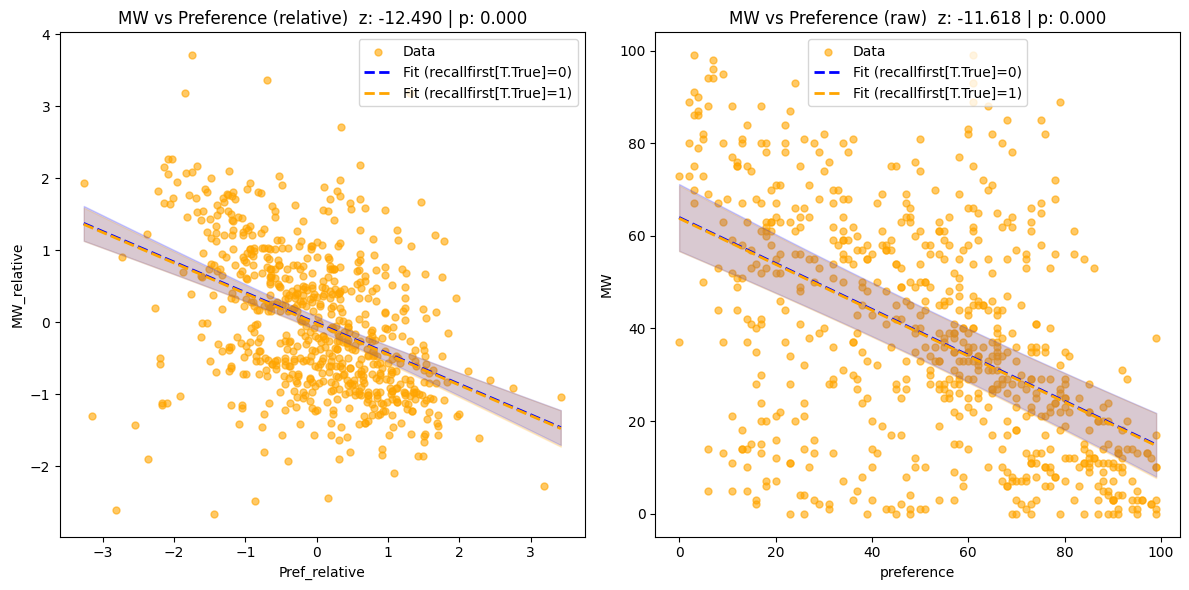

In [5]:


df_current = df_Analysis

### Model Fitting (1)  MW RELATIVE vs PREF RELATIVE 
m = smf.mixedlm("MW_relative ~ Pref_relative+trialNum+recallfirst", data=df_current, groups="Subject").fit()
print(m.summary())   

m2 = smf.mixedlm("MW ~ preference+trialNum+recallfirst", data=df_current,groups="Subject").fit()
print(m2.summary())   

### Write in LOGs 
log_file.write("\n===# (1) MW vs Preference #===\n")
add_result(m,  "Pref_relative", "MW vs Preference", "Relative (z-scored)")
add_result(m2, "preference",    "MW vs Preference", "Raw")


### PLOT RESULTS
fig, ax = plt.subplots(1, 2, figsize=(12,6))
plot_continous_results(m,  df_current, "Pref_relative", "MW_relative", ax[0],
    titl=f"MW vs Preference (relative)  z: {m.tvalues['Pref_relative']:.3f} | p: {m.pvalues['Pref_relative']:.3f}",
    group_param="recallfirst[T.True]")
plot_continous_results(m2, df_current, "preference", "MW", ax[1],
    titl=f"MW vs Preference (raw)  z: {m2.tvalues['preference']:.3f} | p: {m2.pvalues['preference']:.3f}",
    group_param="recallfirst[T.True]")
plt.tight_layout()

Intercept              4.544573
recallfirst[T.True]    1.012678
Pref_relative          1.008134
trialNum               1.006532
dtype: float64
Intercept              8.795726
recallfirst[T.True]    1.007794
preference             1.002065
trialNum               1.005729
dtype: float64


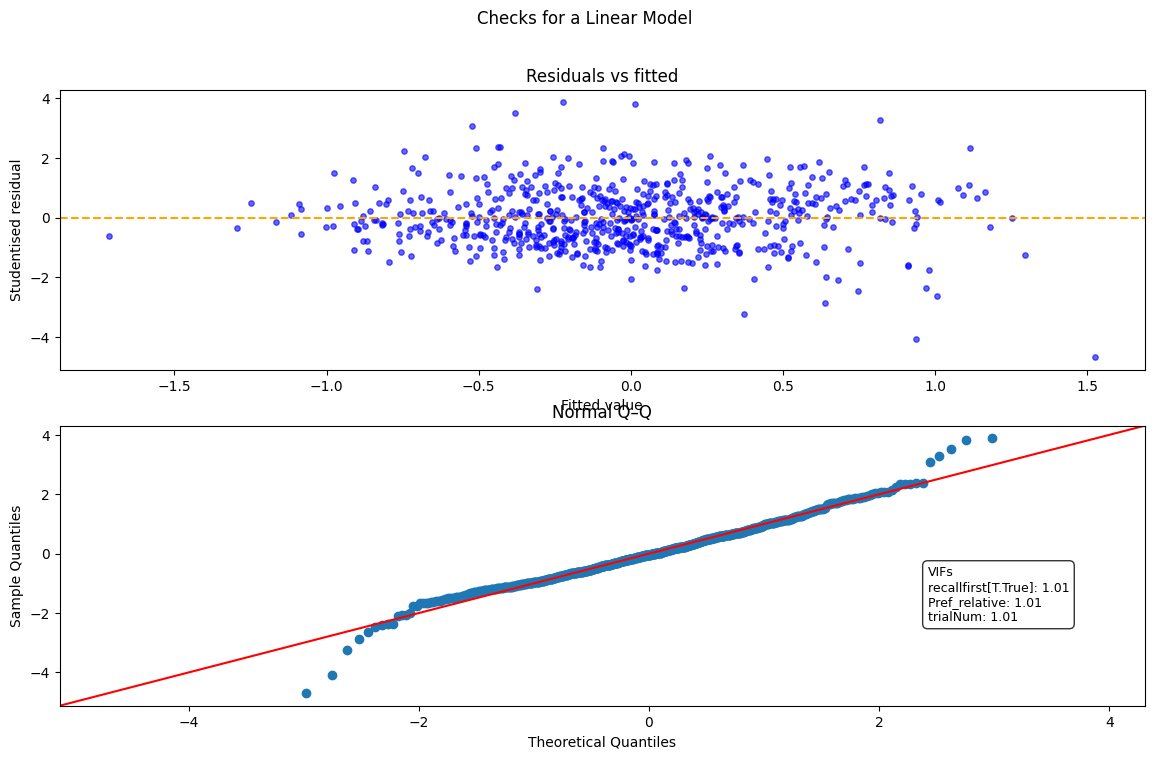

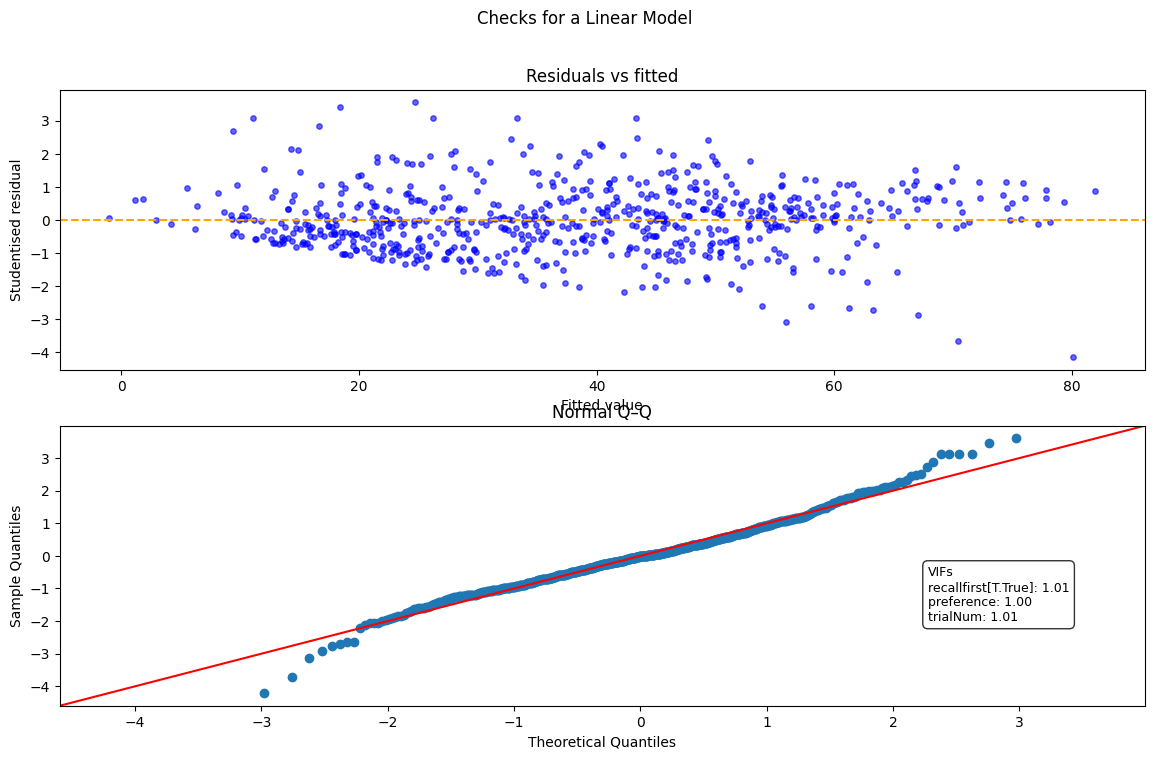

In [6]:
from analysisFunctions import linearModelChecks

linearModelChecks(m,df_current,formula="MW_relative ~ Pref_relative+trialNum+recallfirst")
linearModelChecks(m2,df_current,formula="MW ~ preference+trialNum+recallfirst")


## (2) Is semantic decoupling observed during higher mind wandering?

Semantic measures (computed between each thought report and the story fragment just heard):
- **BERT** – sentence-level cosine *similarity* (higher = thoughts **closer** to the story)
- **WMD** – Word Mover's *distance* on lemmas (higher = thoughts **further** from the story)

A **negative** BERT coefficient and a **positive** WMD coefficient both mean: more MW → more decoupling.
Utterance length (`LemmaLen`) is controlled, as both measures depend on report length.

c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


             Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: semDecoupling_BERT
No. Observations: 686     Method:             REML              
No. Groups:       18      Scale:              0.0093            
Min. group size:  26      Log-Likelihood:     583.6460          
Max. group size:  40      Converged:          Yes               
Mean group size:  38.1                                          
----------------------------------------------------------------
                      Coef.  Std.Err.   z    P>|z| [0.025 0.975]
----------------------------------------------------------------
Intercept              0.365    0.023 16.021 0.000  0.320  0.409
recallfirst[T.True]   -0.023    0.007 -3.151 0.002 -0.038 -0.009
MW_relative           -0.017    0.004 -4.586 0.000 -0.025 -0.010
trialNum              -0.000    0.000 -0.532 0.595 -0.001  0.000
LemmaLen               0.001    0.001  1.619 0.106 -0.000  0.003
Subject Var            0.003    0.013  

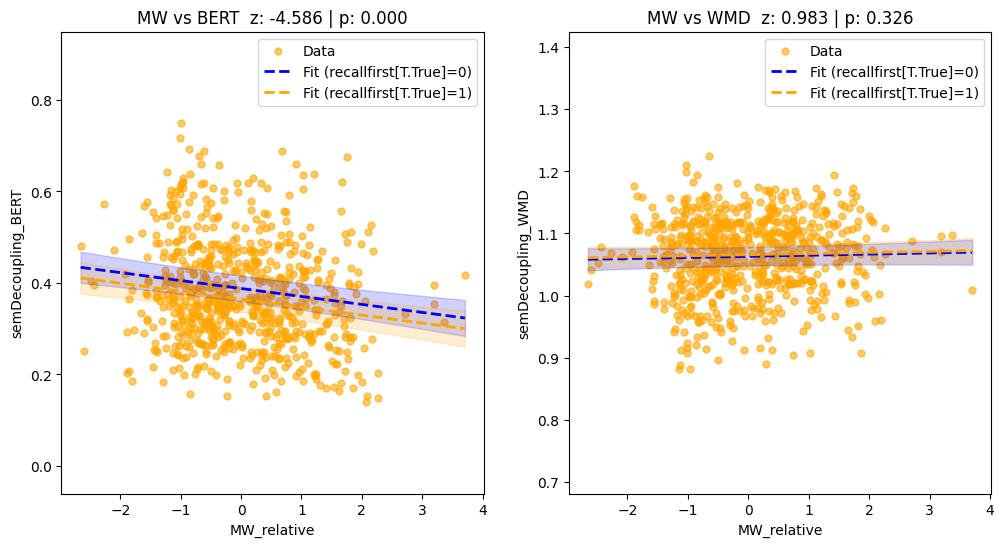

In [7]:
# Add Lemma Length to the DataFrame as a controll of obvious confounder (longer lemmas are more likely to be MW)
df_Analysis['LemmaLen'] = [len(i) for i in df_Analysis['Lemmas'].apply(ast.literal_eval)]
df_current = df_Analysis

### Models:
m_bert = smf.mixedlm("semDecoupling_BERT  ~  MW_relative +trialNum +recallfirst + LemmaLen", data=df_current,groups="Subject").fit()
print(m_bert.summary())   

m_wmd = smf.mixedlm("semDecoupling_WMD  ~ MW_relative +trialNum +recallfirst + LemmaLen", data=df_current,groups="Subject").fit()
print(m_wmd.summary())   

### Log Results:
log_file.write("\n===# (2) Semantic Decoupling vs MW #===\n")
add_result(m_bert, "MW_relative", "Semantic Decoupling vs MW", "BERT")
add_result(m_wmd,  "MW_relative",  "Semantic Decoupling vs MW", "WMD")

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
plot_continous_results(m_bert, df_current, "MW_relative", "semDecoupling_BERT", ax[0],
    titl=f"MW vs BERT  z: {m_bert.tvalues['MW_relative']:.3f} | p: {m_bert.pvalues['MW_relative']:.3f}",
    group_param="recallfirst[T.True]")
plot_continous_results(m_wmd, df_current, "MW_relative", "semDecoupling_WMD", ax[1],
    titl=f"MW vs WMD  z: {m_wmd.tvalues['MW_relative']:.3f} | p: {m_wmd.pvalues['MW_relative']:.3f}",
    group_param="recallfirst[T.True]")
plt.show()

# linearModelChecks(m_bert, df_current, formula="semDecoupling_BERT ~ MW_relative + trialNum + recallfirst + LemmaLen")
# linearModelChecks(m_wmd,  df_current, formula="semDecoupling_WMD ~ MW_relative + trialNum + recallfirst + LemmaLen")

### 2.1 Within-subject centered semantic measures

Semantic measures differ substantially between participants (e.g. general speaking style).
Since MW is z-scored within subjects, the semantic predictors are centered within subjects as well
(`x − subject mean`), so the effect reflects **within-person** fluctuations:
*when a person mind-wanders more than usual, are their thoughts further from the story than usual?*

c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


              Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: semDecoupling_WMD_c
No. Observations: 686     Method:             REML               
No. Groups:       18      Scale:              0.0022             
Min. group size:  26      Log-Likelihood:     1089.1247          
Max. group size:  40      Converged:          Yes                
Mean group size:  38.1                                           
-----------------------------------------------------------------
                       Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-----------------------------------------------------------------
Intercept               0.057    0.011  5.082 0.000  0.035  0.079
recallfirst[T.True]     0.003    0.004  0.722 0.471 -0.004  0.010
MW_relative             0.001    0.002  0.710 0.478 -0.002  0.005
trialNum                0.000    0.000  0.663 0.507 -0.000  0.000
LemmaLen               -0.003    0.001 -6.083 0.000 -0.004 -0.002
Subject Var             

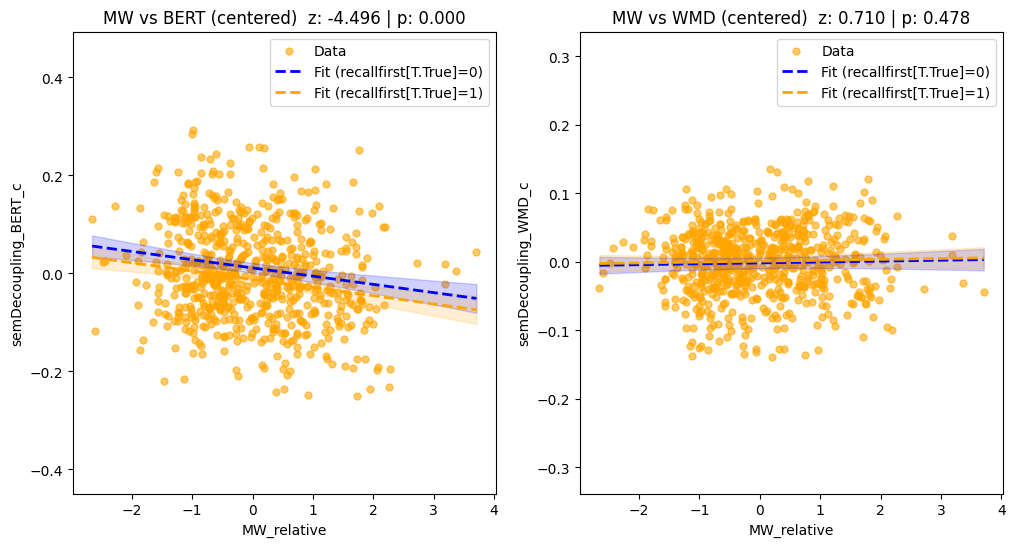

In [8]:
for v in ['semDecoupling_BERT', 'semDecoupling_WMD', 'semDecoupling_W2V']:
    df_Analysis[v + '_c'] = df_Analysis[v] - df_Analysis.groupby('Subject')[v].transform('mean')
df_current = df_Analysis

### Models:
m_bert_c = smf.mixedlm("semDecoupling_BERT_c  ~  MW_relative +trialNum +recallfirst + LemmaLen", data=df_current,groups="Subject").fit()
m_wmd_c = smf.mixedlm("semDecoupling_WMD_c  ~ MW_relative +trialNum +recallfirst + LemmaLen", data=df_current,groups="Subject").fit()
print(m_wmd_c.summary())  ; print(m_bert_c.summary())   


### Log Results:
add_result(m_bert_c, "MW_relative", "Semantic Decoupling vs MW", "BERT (centered)")
add_result(m_wmd_c,  "MW_relative",  "Semantic Decoupling vs MW", "WMD (centered)")


### Plots
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
plot_continous_results(m_bert_c, df_current, "MW_relative", "semDecoupling_BERT_c", ax[0],
    titl=f"MW vs BERT (centered)  z: {m_bert_c.tvalues['MW_relative']:.3f} | p: {m_bert_c.pvalues['MW_relative']:.3f}",
    group_param="recallfirst[T.True]")
plot_continous_results(m_wmd_c, df_current, "MW_relative", "semDecoupling_WMD_c", ax[1],
    titl=f"MW vs WMD (centered)  z: {m_wmd_c.tvalues['MW_relative']:.3f} | p: {m_wmd_c.pvalues['MW_relative']:.3f}",
    group_param="recallfirst[T.True]")
plt.show()

# linearModelChecks(m_bert_c, df_current, formula="semDecoupling_BERT_c ~ MW_relative + trialNum + recallfirst + LemmaLen")
# linearModelChecks(m_wmd_c,  df_current, formula="semDecoupling_WMD_c ~ MW_relative + trialNum + recallfirst + LemmaLen")

### (3) Does preference moderate the semantic decoupling – MW relation?

Interaction model: `MW ~ BERT_c × Preference`. This tests **moderation**
(does the BERT–MW relation depend on how interesting the fragment was?), **not mediation**.
The centered BERT measure is used so that the main effect of preference is evaluated
at the participant's average semantic similarity (not at BERT = 0, which does not occur in the data).

c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


               Mixed Linear Model Regression Results
Model:              MixedLM  Dependent Variable:  semDecoupling_BERT
No. Observations:   686      Method:              REML              
No. Groups:         18       Scale:               0.0091            
Min. group size:    26       Log-Likelihood:      584.6768          
Max. group size:    40       Converged:           Yes               
Mean group size:    38.1                                            
--------------------------------------------------------------------
                          Coef.  Std.Err.   z    P>|z| [0.025 0.975]
--------------------------------------------------------------------
Intercept                  0.375    0.023 16.408 0.000  0.330  0.420
recallfirst[T.True]       -0.021    0.007 -2.819 0.005 -0.035 -0.006
MW_relative               -0.008    0.004 -1.843 0.065 -0.016  0.001
Pref_relative              0.019    0.004  4.495 0.000  0.010  0.027
MW_relative:Pref_relative  0.005    0.003  1.385 0

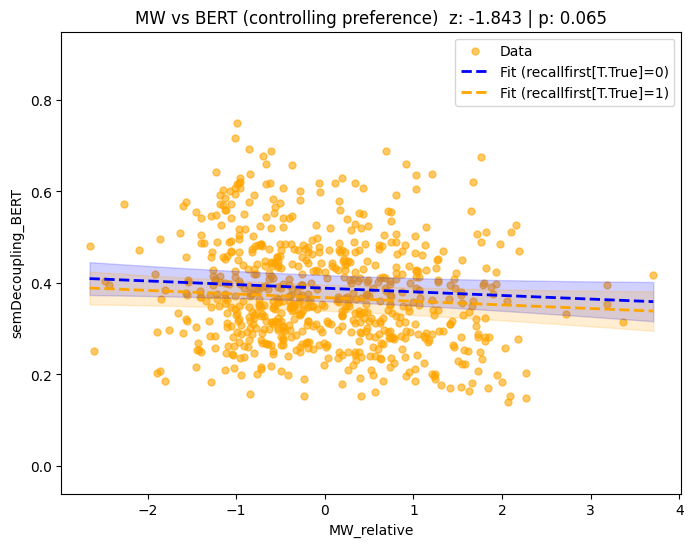

In [9]:
df_current = df_Analysis

m_mod = smf.mixedlm(" semDecoupling_BERT~ MW_relative *Pref_relative +trialNum +recallfirst + LemmaLen", data=df_current, groups="Subject").fit()
print(m_mod.summary())   

log_file.write("\n===# (3) Moderation: BERT x Preference #===\n")
add_result(m_mod, "MW_relative:Pref_relative", "BERT x Preference", "Interaction")
add_result(m_mod, "MW_relative",               "BERT x Preference", "BERT_c (at mean preference)")
add_result(m_mod, "Pref_relative",                      "BERT x Preference", "Preference (at mean BERT)")

fig, ax = plt.subplots(1, 1, figsize=(8, 6))
plot_continous_results(m_mod, df_current, "MW_relative", "semDecoupling_BERT", ax,
    titl=f"MW vs BERT (controlling preference)  z: {m_mod.tvalues['MW_relative']:.3f} | p: {m_mod.pvalues['MW_relative']:.3f}",
    group_param="recallfirst[T.True]")

## (4) Replication with attention ratings

Thought reports were coded for attentional focus by one trained judge
(1 = focus, 2 = task-related thoughts, 3 = mind wandering, 4 = mind blanking).
For analysis they are collapsed into **on-task (1–2)** vs **off-task (3–4)** (`Attention2`).

### (4.1) Attention vs MW rating

                            OLS Regression Results                            
Dep. Variable:            MW_relative   R-squared:                       0.125
Model:                            OLS   Adj. R-squared:                  0.122
Method:                 Least Squares   F-statistic:                     17.84
Date:                Tue, 03 Nov 2026   Prob (F-statistic):           6.69e-05
Time:                        09:36:31   Log-Likelihood:                -927.56
No. Observations:                 686   AIC:                             1861.
Df Residuals:                     683   BIC:                             1875.
Df Model:                           2                                         
Covariance Type:              cluster                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             -0.6356      0

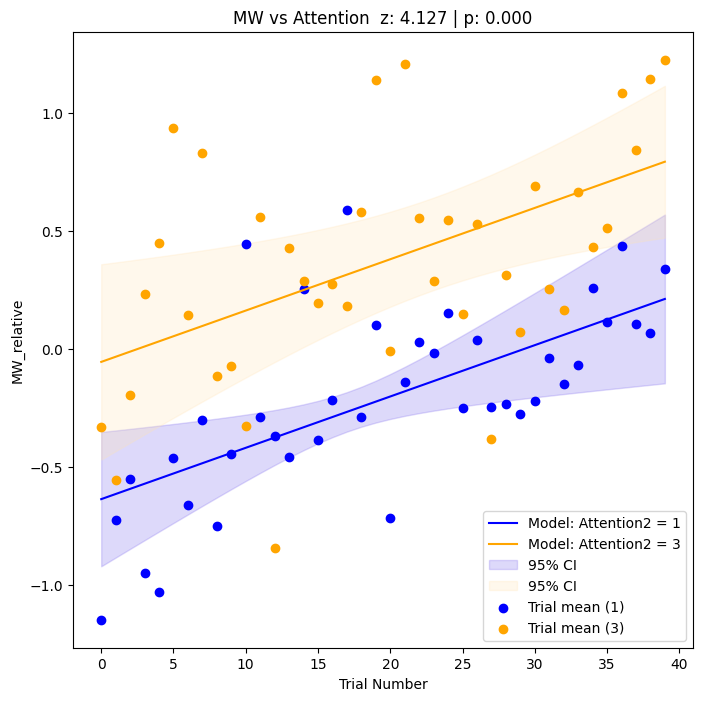

In [10]:
from analysisFunctions import plotTrialTrack
df_current['Attention2'] = [1  if (att == 1 or att == 2) else 3 for att in df_current['Attention']]

m_att_ols = smf.ols("MW_relative ~ C(Attention2) + trialNum", data=df_current).fit(
    cov_type="cluster", cov_kwds={"groups": df_current["Subject"]})
print(m_att_ols.summary())

log_file.write("\n===# (4) Attention replications #===\n")
add_result(m_att_ols, "C(Attention2)[T.3]", "Attention vs", "MW rating (OLS, cluster SE)")

fig, ax = plt.subplots(figsize=(8, 8))
plotTrialTrack(m_att_ols, 'MW_relative', df_current, ax,
    titl=f"MW vs Attention  z: {m_att_ols.tvalues['C(Attention2)[T.3]']:.3f} | p: {m_att_ols.pvalues['C(Attention2)[T.3]']:.3f}",
    firstContrast=1, lastContrast=3, anlysisName="Attention2", paramNum=[0, 1, 2])

#### (4.2) Attention vs semantic decoupling

Are off-task reports semantically further from the story than on-task reports?
(BERT: lower similarity expected; WMD: higher distance expected.)

c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


             Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: semDecoupling_BERT
No. Observations: 686     Method:             REML              
No. Groups:       18      Scale:              0.0091            
Min. group size:  26      Log-Likelihood:     593.3266          
Max. group size:  40      Converged:          Yes               
Mean group size:  38.1                                          
----------------------------------------------------------------
                      Coef.  Std.Err.   z    P>|z| [0.025 0.975]
----------------------------------------------------------------
Intercept              0.383    0.022 17.644 0.000  0.341  0.426
C(Attention2)[T.3]    -0.053    0.008 -6.285 0.000 -0.069 -0.036
recallfirst[T.True]   -0.025    0.007 -3.418 0.001 -0.039 -0.011
trialNum              -0.001    0.000 -2.310 0.021 -0.001 -0.000
LemmaLen               0.002    0.001  2.380 0.017  0.000  0.004
Subject Var            0.003    0.011  

c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


             Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: semDecoupling_W2V
No. Observations: 686     Method:             REML             
No. Groups:       18      Scale:              0.0011           
Min. group size:  26      Log-Likelihood:     1335.8000        
Max. group size:  40      Converged:          Yes              
Mean group size:  38.1                                         
---------------------------------------------------------------
                     Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------------
Intercept             0.492    0.006 76.774 0.000  0.479  0.504
C(Attention2)[T.3]   -0.002    0.003 -0.589 0.556 -0.007  0.004
recallfirst[T.True]   0.000    0.002  0.037 0.970 -0.005  0.005
trialNum              0.000    0.000  1.739 0.082 -0.000  0.000
LemmaLen              0.000    0.000  0.312 0.755 -0.000  0.001
Subject Var           0.000    0.002                 

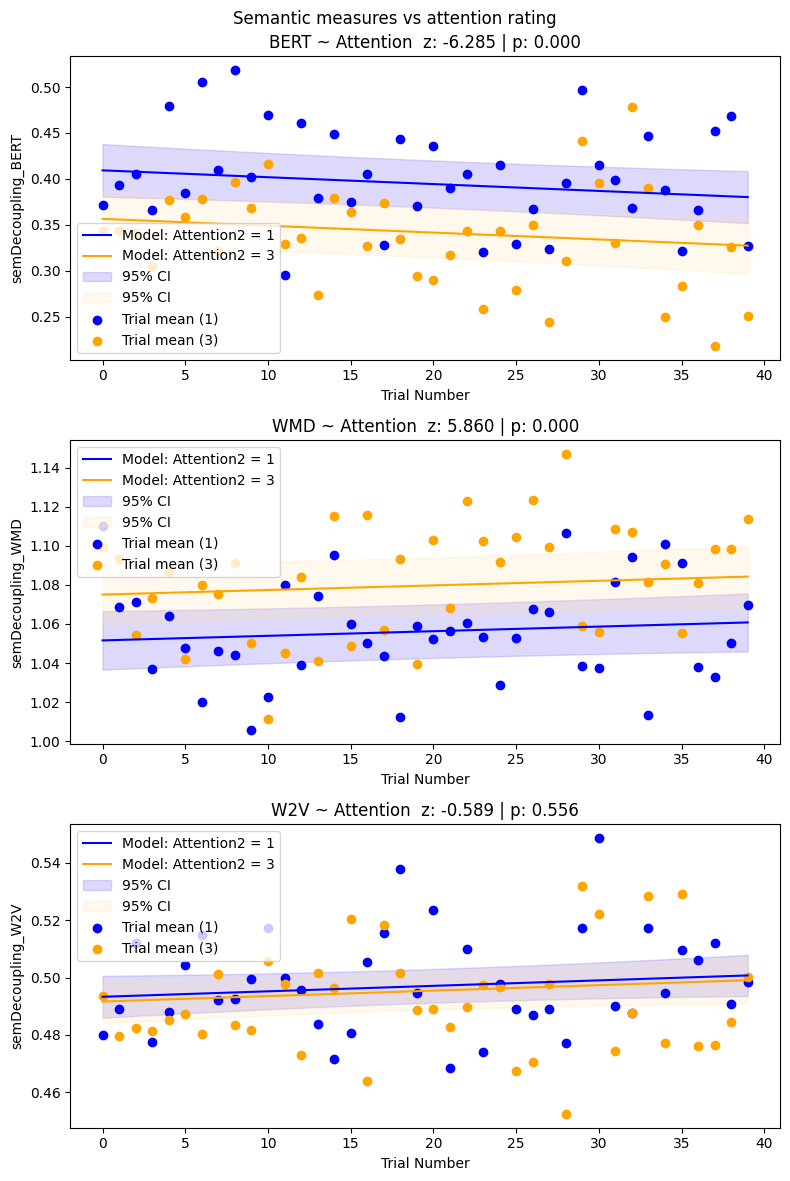

In [11]:
df_current = df_Analysis.dropna(subset=['Attention2'])
fig, ax = plt.subplots(3, 1, figsize=(8, 12))
plt.suptitle("Semantic measures vs attention rating")

for i, (label, v) in enumerate([("BERT", "semDecoupling_BERT"), ("WMD", "semDecoupling_WMD"), ("W2V", "semDecoupling_W2V")]):
    mm = smf.mixedlm(f"{v} ~ C(Attention2) + recallfirst + trialNum + LemmaLen", data=df_current, groups="Subject").fit()
    print(mm.summary())
    add_result(mm, "C(Attention2)[T.3]", "Attention vs", label)
    plotTrialTrack(mm, v, df_current, ax[i],
        titl=f"{label} ~ Attention  z: {mm.tvalues['C(Attention2)[T.3]']:.3f} | p: {mm.pvalues['C(Attention2)[T.3]']:.3f}",
        firstContrast=1, lastContrast=3, anlysisName="Attention2", paramNum=[0, 1, 3],
        covariates={'LemmaLen': df_current['LemmaLen'].mean(),
                    'recallfirst[T.True]': df_current['recallfirst'].mean()})
plt.tight_layout()

#### (4.3) Preference vs attention rating

Were fragments rated as more interesting when the report was coded as on-task?

c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)


             Mixed Linear Model Regression Results
Model:              MixedLM  Dependent Variable:  Pref_relative
No. Observations:   686      Method:              REML         
No. Groups:         18       Scale:               0.9503       
Min. group size:    26       Log-Likelihood:      -964.3796    
Max. group size:    40       Converged:           Yes          
Mean group size:    38.1                                       
---------------------------------------------------------------
                    Coef.  Std.Err.    z    P>|z| [0.025 0.975]
---------------------------------------------------------------
Intercept            0.310    0.081   3.806 0.000  0.150  0.469
C(Attention2)[T.3]  -0.417    0.029 -14.573 0.000 -0.474 -0.361
recallfirst[T.True] -0.171    0.075  -2.290 0.022 -0.317 -0.025
trialNum            -0.004    0.003  -1.325 0.185 -0.011  0.002
Subject Var          0.000                                     



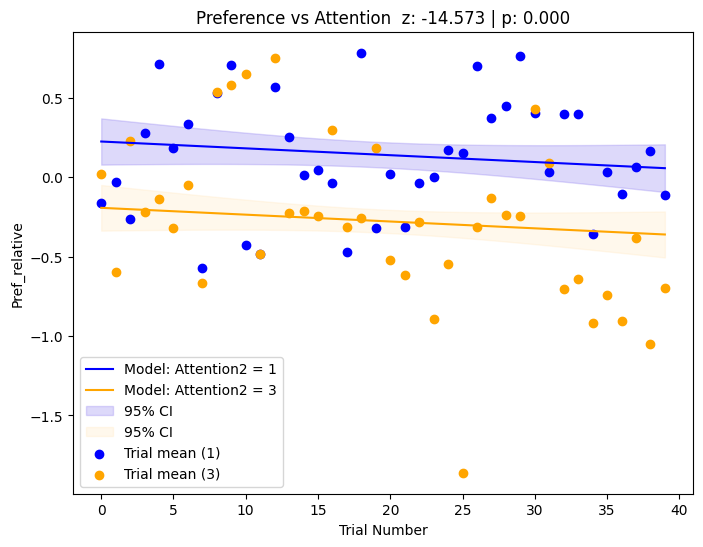

In [12]:
df_current = df_Analysis.dropna(subset=['Attention2'])

m_pref = smf.mixedlm("Pref_relative ~ C(Attention2) + recallfirst + trialNum", data=df_current, groups="Subject").fit()
print(m_pref.summary())
add_result(m_pref, "C(Attention2)[T.3]", "Attention vs", "Preference")

fig, ax = plt.subplots(figsize=(8, 6))
plotTrialTrack(m_pref, 'Pref_relative', df_current, ax,
    titl=f"Preference vs Attention  z: {m_pref.tvalues['C(Attention2)[T.3]']:.3f} | p: {m_pref.pvalues['C(Attention2)[T.3]']:.3f}",
    firstContrast=1, lastContrast=3, anlysisName="Attention2", paramNum=[0, 1, 3],
    covariates={'recallfirst[T.True]': df_current['recallfirst'].mean()})

## 5 Semantic Similarity in Temporal Lags: 


### 5.1 Semantic Similarity to Previous and next trials

Here, we compute Semantic Similarity  TO PREVIOUS  and NEXT TRIALS  - 4 x 2 (-2,-1,+1,+2).

Each acheieve similari as before 

c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)


===== BERT -4 =====
                Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: semDecoupling_BERT_p4_c
No. Observations: 614     Method:             REML                   
No. Groups:       18      Scale:              0.0078                 
Min. group size:  22      Log-Likelihood:     596.2004               
Max. group size:  36      Converged:          Yes                    
Mean group size:  34.1                                               
------------------------------------------------------------------------
               Coef.     Std.Err.      z       P>|z|    [0.025    0.975]
------------------------------------------------------------------------
Intercept       0.008       0.014     0.602    0.547    -0.019     0.036
MW_relative    -0.008       0.004    -2.105    0.035    -0.015    -0.001
trialNum       -0.001       0.000    -1.486    0.137    -0.001     0.000
LemmaLen        0.000       0.001     0.282    0.778    -0.001     0

c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with cg
  warnings.warn(
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\s

===== WMD -4 =====
               Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: semDecoupling_WMD_p4_c
No. Observations: 614     Method:             REML                  
No. Groups:       18      Scale:              0.0014                
Min. group size:  22      Log-Likelihood:     1103.9479             
Max. group size:  36      Converged:          No                    
Mean group size:  34.1                                              
----------------------------------------------------------------------
                  Coef.    Std.Err.     z      P>|z|   [0.025   0.975]
----------------------------------------------------------------------
Intercept          0.057      0.010    5.963   0.000    0.038    0.076
MW_relative       -0.001      0.002   -0.675   0.500   -0.004    0.002
trialNum           0.000      0.000    2.323   0.020    0.000    0.001
LemmaLen          -0.004      0.000   -8.133   0.000   -0.004   -0.003
Subject Var      

c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2054: UserWarning: The random effects covariance matrix is singular.
  warnings.warn(_warn_cov_sing)
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_mode

===== BERT -3 =====
                Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: semDecoupling_BERT_p3_c
No. Observations: 632     Method:             REML                   
No. Groups:       18      Scale:              0.0060                 
Min. group size:  23      Log-Likelihood:     inf                    
Max. group size:  37      Converged:          Yes                    
Mean group size:  35.1                                               
------------------------------------------------------------------------
               Coef.     Std.Err.      z       P>|z|    [0.025    0.975]
------------------------------------------------------------------------
Intercept       0.000                                                   
MW_relative    -0.005       0.003    -1.610    0.107    -0.011     0.001
trialNum       -0.001       0.000    -1.811    0.070    -0.001     0.000
LemmaLen        0.002       0.001     2.249    0.024     0.000     0

... (16 outputs left out)

c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with cg
  warnings.warn(
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\s

===== WMD +3 =====
               Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: semDecoupling_WMD_n3_c
No. Observations: 638     Method:             REML                  
No. Groups:       18      Scale:              0.0011                
Min. group size:  23      Log-Likelihood:     1242.7442             
Max. group size:  37      Converged:          No                    
Mean group size:  35.4                                              
----------------------------------------------------------------------
                  Coef.    Std.Err.     z      P>|z|   [0.025   0.975]
----------------------------------------------------------------------
Intercept          0.051      0.008    6.538   0.000    0.035    0.066
MW_relative       -0.001      0.001   -1.053   0.292   -0.004    0.001
trialNum           0.000      0.000    0.732   0.464   -0.000    0.000
LemmaLen          -0.003      0.000   -7.743   0.000   -0.004   -0.002
Subject Var      

c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2054: UserWarning: The random effects covariance matrix is singular.
  warnings.warn(_warn_cov_sing)
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2245: UserWarning: The random effects covariance matrix is singular.
  warnings.warn(_warn_cov_sing)
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_mo

===== BERT +4 =====
                Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: semDecoupling_BERT_n4_c
No. Observations: 622     Method:             REML                   
No. Groups:       18      Scale:              0.0083                 
Min. group size:  22      Log-Likelihood:     inf                    
Max. group size:  36      Converged:          Yes                    
Mean group size:  34.6                                               
------------------------------------------------------------------------
               Coef.     Std.Err.      z       P>|z|    [0.025    0.975]
------------------------------------------------------------------------
Intercept      -0.000                                                   
MW_relative    -0.011       0.004    -2.848    0.004    -0.019    -0.003
trialNum       -0.001       0.000    -2.278    0.023    -0.002    -0.000
LemmaLen       -0.001       0.001    -1.609    0.108    -0.003     0

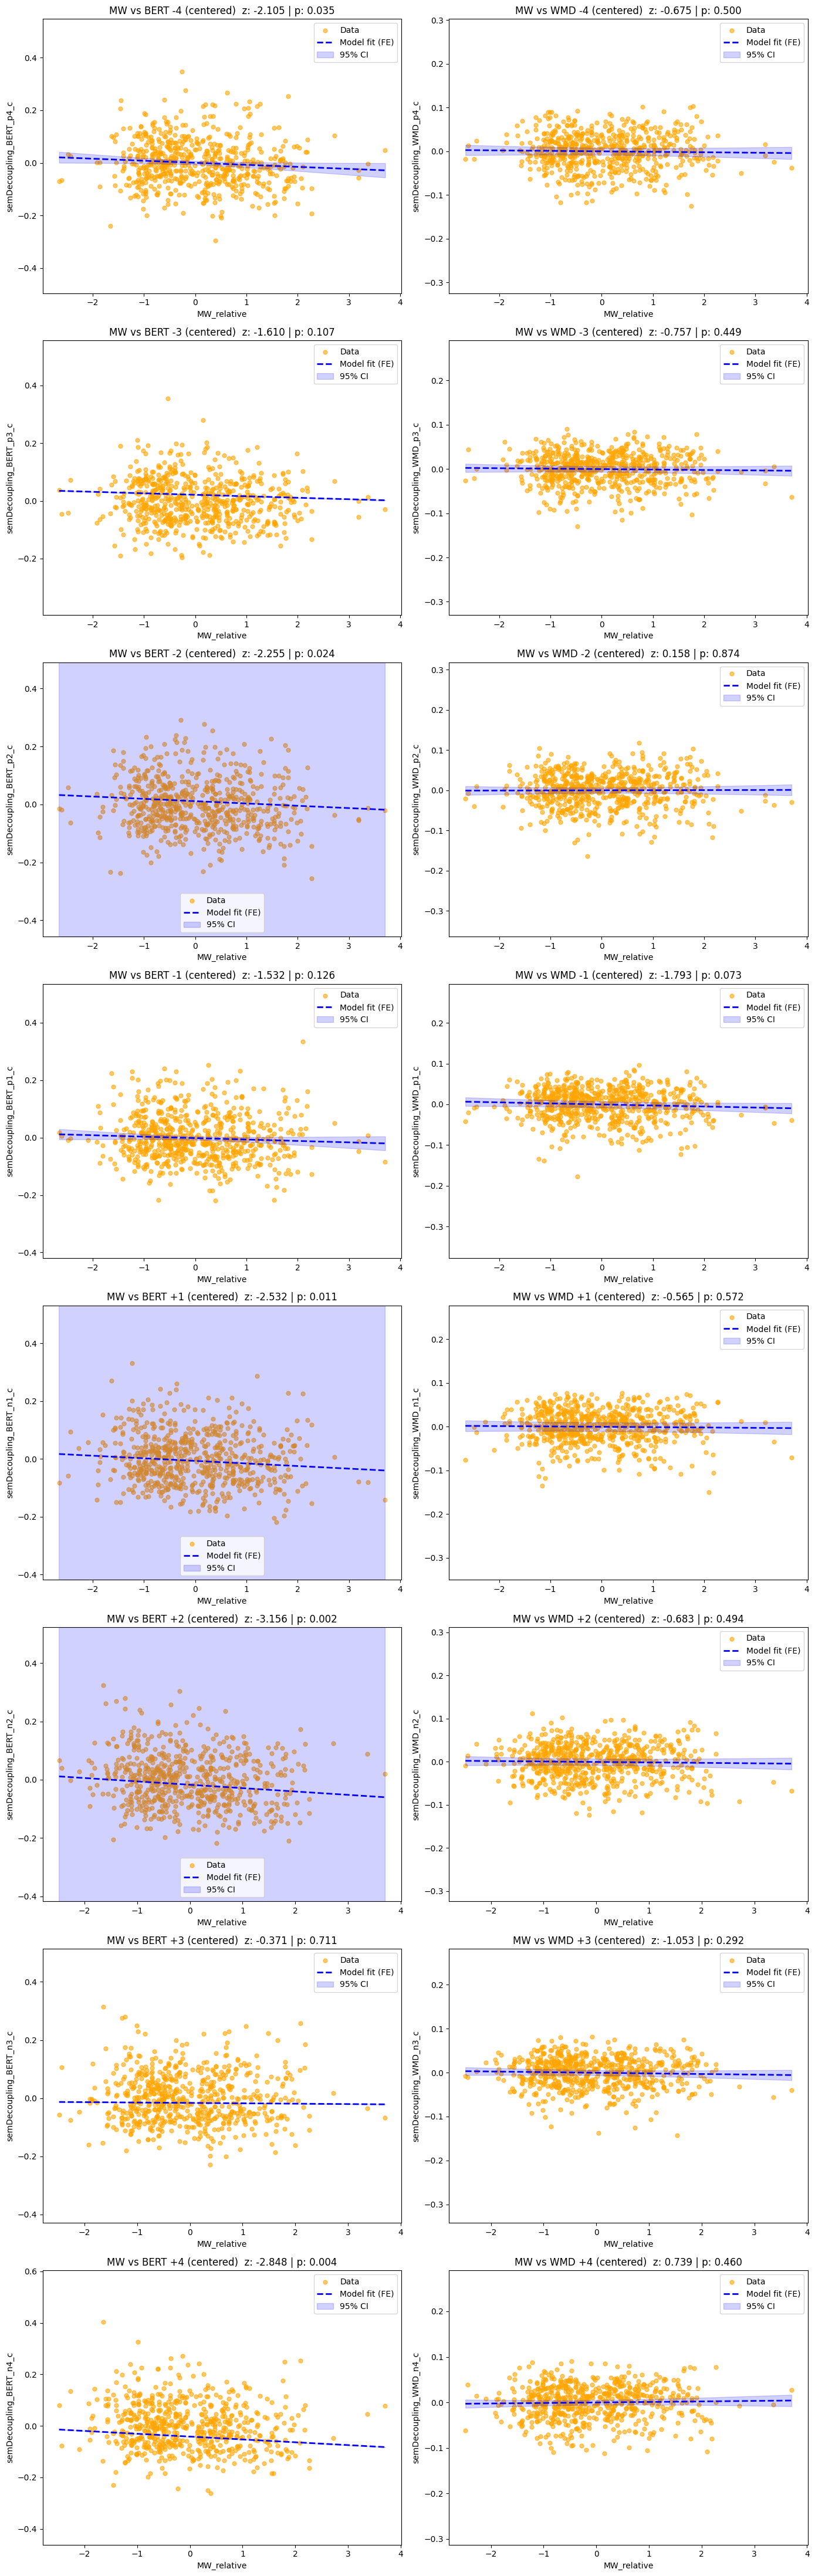

In [13]:
# All neighbour lags present in the data (+-2 now, +-4 after re-running storyDataExtraction.py)
offsets = [(f"{'p' if l < 0 else 'n'}{abs(l)}", f"{l:+d}") for l in [-4, -3, -2, -1, 1, 2, 3, 4]
           if f"semDecoupling_BERT_{'p' if l < 0 else 'n'}{abs(l)}" in df_Analysis.columns]
measures = [('BERT', 'semDecoupling_BERT'), ('WMD', 'semDecoupling_WMD')]

# Within-subject centering for every neighbour-segment similarity
for _, v in measures + [('W2V', 'semDecoupling_W2V')]:
    for off, _ in offsets:
        df_Analysis[f"{v}_{off}_c"] = df_Analysis[f"{v}_{off}"] - df_Analysis.groupby('Subject')[f"{v}_{off}"].transform('mean')

log_file.write("===# (3) Semantic similarity to neighbouring segments vs MW #===\n")
models_nb = {}
fig, ax = plt.subplots(len(offsets), 2, figsize=(14, 5.5*len(offsets)), squeeze=False)

for r, (off, offLabel) in enumerate(offsets):
    for c, (label, v) in enumerate(measures):
        x = f"{v}_{off}_c"
        df_current = df_Analysis.dropna(subset=[x])   # edge trials have no -2/-1/+1/+2 neighbour

        ### Model:
        m = smf.mixedlm(f"{x} ~  MW_relative + trialNum  + LemmaLen", data=df_current, groups="Subject").fit()
        print(f"===== {label} {offLabel} ====="); print(m.summary())
        models_nb[(label, off)] = m

        ### Log Results:
        add_result(m, "MW_relative", "Neighbour similarity vs MW", f"{label} {offLabel} (centered)")

        ### Plot:
        plot_continous_results(m, df_current, "MW_relative", x , ax[r, c],
            titl=f"MW vs {label} {offLabel} (centered)  z: {m.tvalues['MW_relative']:.3f} | p: {m.pvalues['MW_relative']:.3f}",
            )

plt.tight_layout()
plt.show()


### 5.3 Semantic Similarity to Previous and next trials with COntrolled Preference 


c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)


===== BERT -4 =====
                Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: semDecoupling_BERT_p4_c
No. Observations: 614     Method:             REML                   
No. Groups:       18      Scale:              0.0078                 
Min. group size:  22      Log-Likelihood:     594.5453               
Max. group size:  36      Converged:          Yes                    
Mean group size:  34.1                                               
-----------------------------------------------------------------------
                   Coef.    Std.Err.     z      P>|z|   [0.025   0.975]
-----------------------------------------------------------------------
Intercept           0.009      0.014    0.670   0.503   -0.018    0.036
MW_relative        -0.003      0.004   -0.802   0.423   -0.011    0.005
trialNum           -0.001      0.000   -1.505   0.132   -0.001    0.000
Pref_relative       0.010      0.004    2.422   0.015    0.002    0.018
Le

c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with cg
  warnings.warn(
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\s

===== WMD -4 =====
               Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: semDecoupling_WMD_p4_c
No. Observations: 614     Method:             REML                  
No. Groups:       18      Scale:              0.0014                
Min. group size:  22      Log-Likelihood:     1098.8519             
Max. group size:  36      Converged:          No                    
Mean group size:  34.1                                              
----------------------------------------------------------------------
                  Coef.    Std.Err.     z      P>|z|   [0.025   0.975]
----------------------------------------------------------------------
Intercept          0.056      0.010    5.844   0.000    0.037    0.075
MW_relative       -0.002      0.002   -0.959   0.338   -0.005    0.002
trialNum           0.000      0.000    2.330   0.020    0.000    0.001
Pref_relative     -0.001      0.002   -0.789   0.430   -0.005    0.002
LemmaLen         

c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2054: UserWarning: The random effects covariance matrix is singular.
  warnings.warn(_warn_cov_sing)
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_mode

===== BERT -3 =====
                Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: semDecoupling_BERT_p3_c
No. Observations: 632     Method:             REML                   
No. Groups:       18      Scale:              0.0060                 
Min. group size:  23      Log-Likelihood:     inf                    
Max. group size:  37      Converged:          Yes                    
Mean group size:  35.1                                               
-----------------------------------------------------------------------
                   Coef.    Std.Err.     z      P>|z|   [0.025   0.975]
-----------------------------------------------------------------------
Intercept          -0.000                                              
MW_relative        -0.007      0.004   -2.088   0.037   -0.015   -0.000
trialNum           -0.001      0.000   -1.787   0.074   -0.001    0.000
Pref_relative      -0.005      0.004   -1.441   0.150   -0.012    0.002
Le

... (14 outputs left out)

c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


===== BERT +3 =====
                Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: semDecoupling_BERT_n3_c
No. Observations: 638     Method:             REML                   
No. Groups:       18      Scale:              0.0075                 
Min. group size:  23      Log-Likelihood:     628.2478               
Max. group size:  37      Converged:          Yes                    
Mean group size:  35.4                                               
-----------------------------------------------------------------------
                   Coef.    Std.Err.     z      P>|z|   [0.025   0.975]
-----------------------------------------------------------------------
Intercept           0.000      0.012    0.000   1.000   -0.023    0.023
MW_relative        -0.001      0.004   -0.222   0.824   -0.009    0.007
trialNum           -0.001      0.000   -2.626   0.009   -0.002   -0.000
Pref_relative       0.001      0.004    0.232   0.817   -0.007    0.009
Le

c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2054: UserWarning: The random effects covariance matrix is singular.
  warnings.warn(_warn_cov_sing)
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_mode

===== BERT +4 =====
                Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: semDecoupling_BERT_n4_c
No. Observations: 622     Method:             REML                   
No. Groups:       18      Scale:              0.0082                 
Min. group size:  22      Log-Likelihood:     inf                    
Max. group size:  36      Converged:          Yes                    
Mean group size:  34.6                                               
-----------------------------------------------------------------------
                   Coef.    Std.Err.     z      P>|z|   [0.025   0.975]
-----------------------------------------------------------------------
Intercept           0.000                                              
MW_relative        -0.007      0.004   -1.689   0.091   -0.016    0.001
trialNum           -0.001      0.000   -2.443   0.015   -0.002   -0.000
Pref_relative       0.008      0.004    1.879   0.060   -0.000    0.016
Le

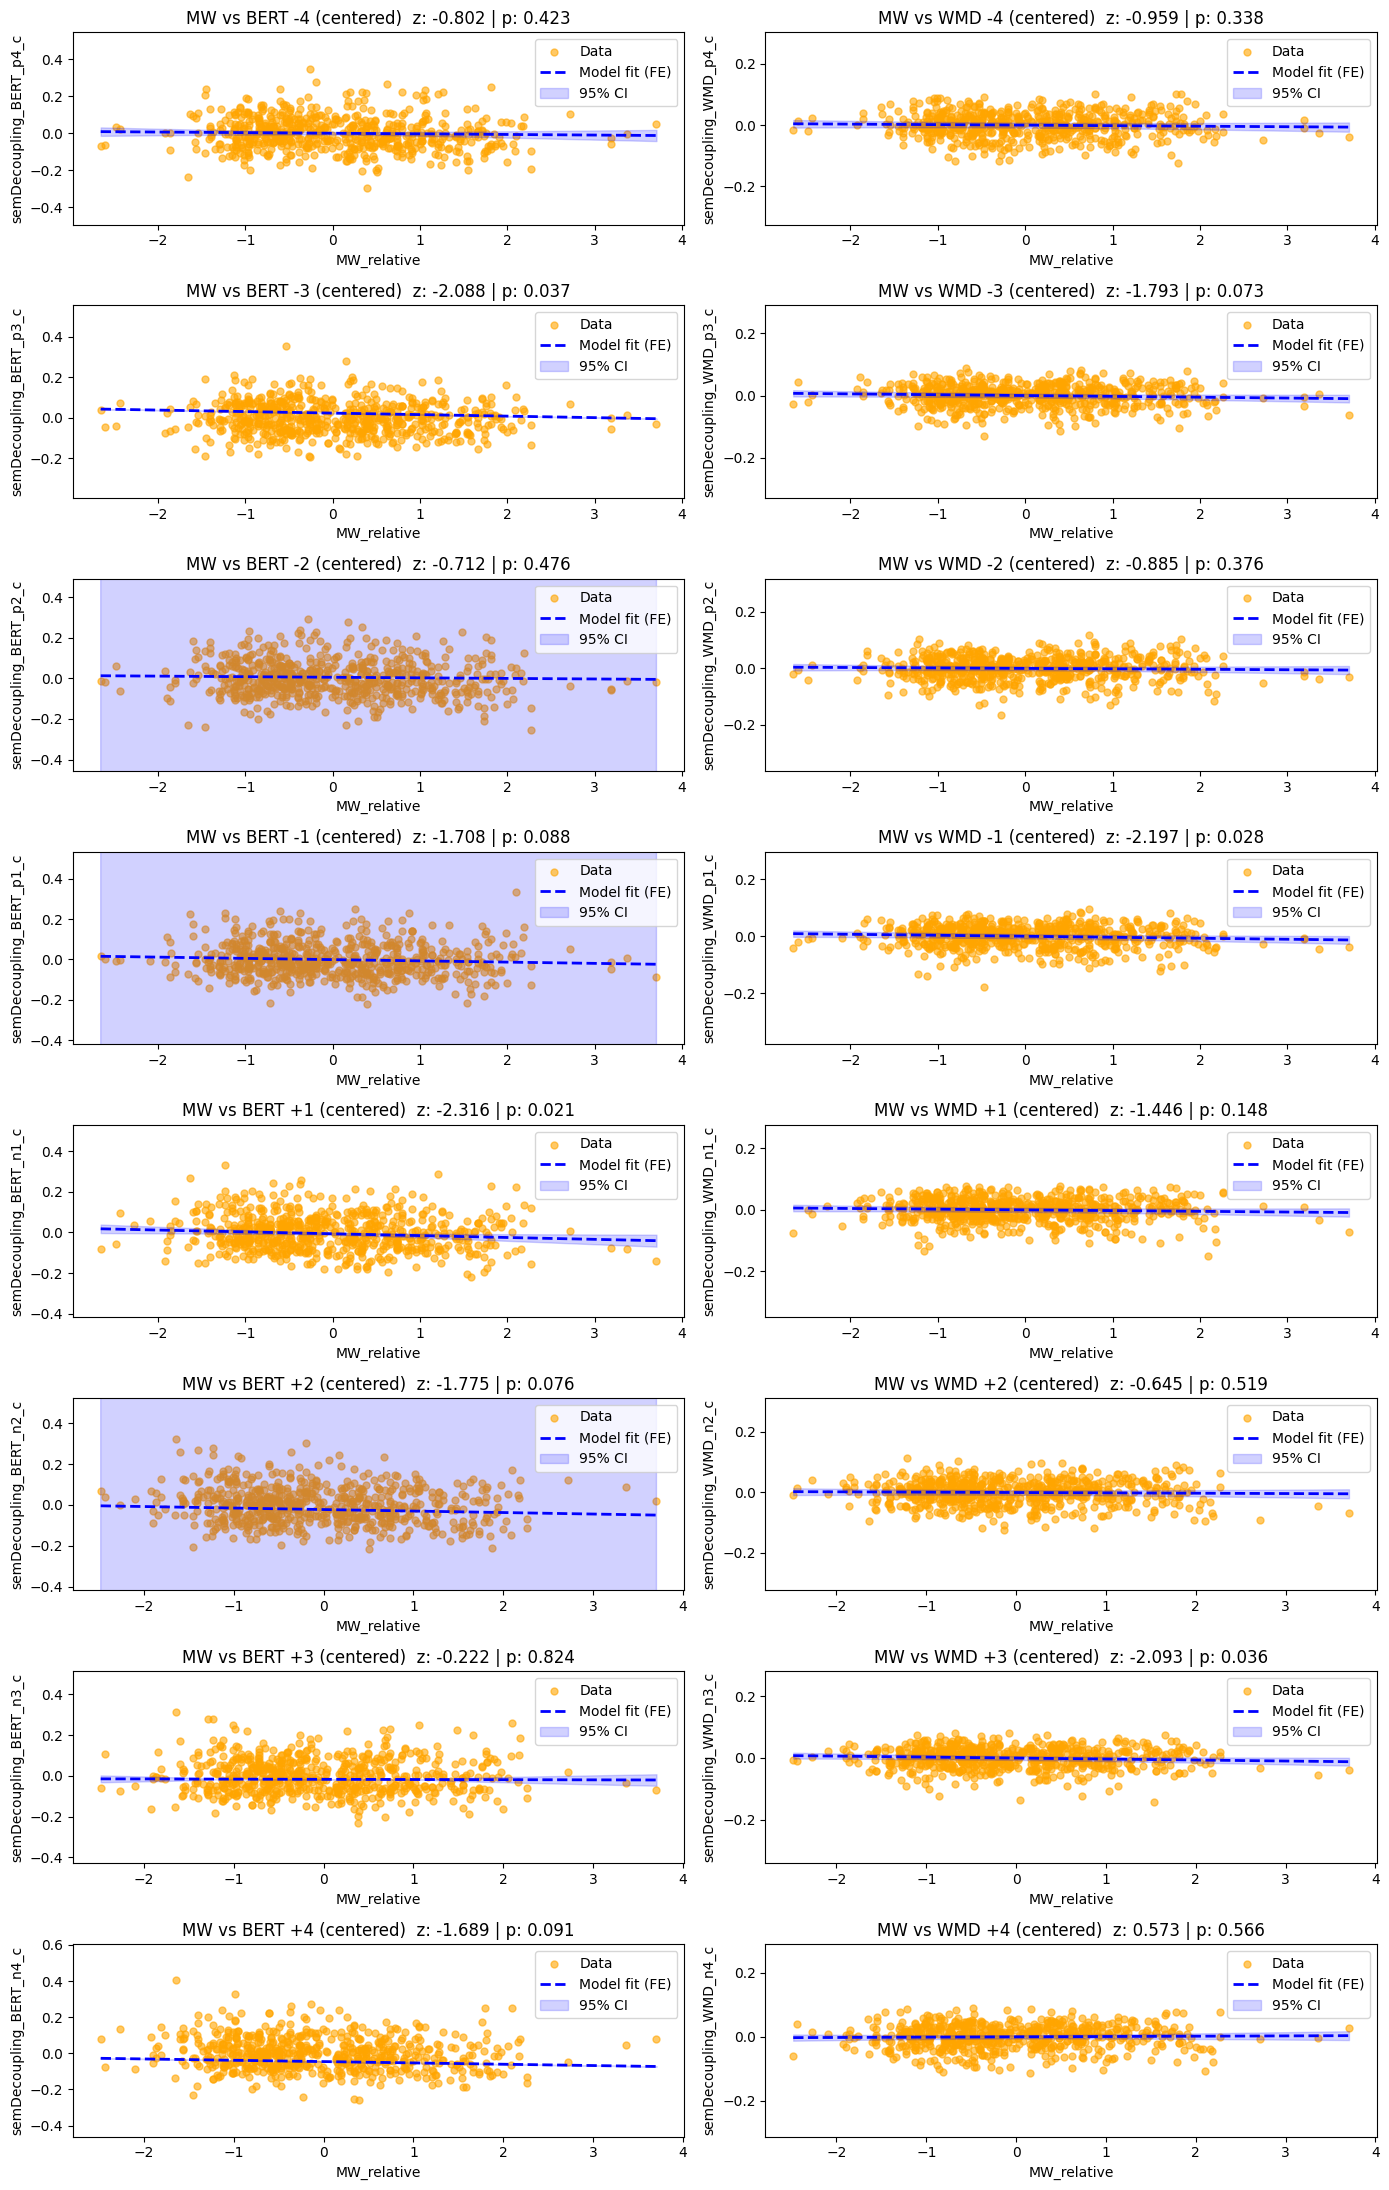

In [14]:
offsets =[ ('p4', '-4'),('p3', '-3'),('p2', '-2'), ('p1', '-1'), ('n1', '+1'), ('n2', '+2'), ('n3', '+3'), ('n4', '+4')]
measures = [('BERT', 'semDecoupling_BERT'), ('WMD', 'semDecoupling_WMD')]

# Within-subject centering for every neighbour-segment similarity
for _, v in measures + [('W2V', 'semDecoupling_W2V')]:
    for off, _ in offsets:
        df_Analysis[f"{v}_{off}_c"] = df_Analysis[f"{v}_{off}"] - df_Analysis.groupby('Subject')[f"{v}_{off}"].transform('mean')

log_file.write("===# (3) Semantic similarity to neighbouring segments vs MW #===\n")
models_nb = {}
fig, ax = plt.subplots(8, 2, figsize=(14, 22))

for r, (off, offLabel) in enumerate(offsets):
    for c, (label, v) in enumerate(measures):
        x = f"{v}_{off}_c"
        df_current = df_Analysis.dropna(subset=[x])   # edge trials have no -2/-1/+1/+2 neighbour

        ### Model:
        m = smf.mixedlm(f"{x} ~  MW_relative + trialNum +Pref_relative  + LemmaLen", data=df_current, groups="Subject").fit()
        print(f"===== {label} {offLabel} ====="); print(m.summary())
        models_nb[(label, off)] = m

        ### Log Results:
        add_result(m, "MW_relative", "Neighbour similarity vs MW", f"{label} {offLabel} (centered)")

        ### Plot:
        plot_continous_results(m, df_current, "MW_relative", x , ax[r, c],
            titl=f"MW vs {label} {offLabel} (centered)  z: {m.tvalues['MW_relative']:.3f} | p: {m.pvalues['MW_relative']:.3f}")

plt.tight_layout()
plt.show()


### 5.4  Lag Analysis

**Aim.** To disentangle *where* MW-related semantic decoupling occurs: does MW reduce the similarity of thoughts
only to the fragment just heard (lag 0), or also to preceding (−2, −1) and following (+1, +2) fragments?
If thoughts during MW dwelt on earlier parts of the story, the MW effect should be weaker for past than for future fragments.

#### Model

Data are in long format: each thought report appears five times, once per lag.

`Similarity ~ 0 + C(lag) + C(lag):MW_relative + trialNum + LemmaLen + (1 + MW_relative | Subject) + (1 | Subject:trial_id)`

- `0 + C(lag)`: a separate intercept for each lag (no common intercept)
- `C(lag):MW_relative`: a separate **MW slope** for each lag (the change in similarity per 1-point increase in MW)
- `trialNum`: time on task; `LemmaLen`: length of the thought report
- `(1 + MW_relative | Subject)`: random intercept and random MW slope per participant
- `(1 | Subject:trial_id)`: random intercept for each thought report, as the same report enters the data five times

MW_relative is centred within participants.

#### Tests

All tests are Wald tests on linear combinations of the fixed effects (r·β), with SE = √(r′Vr),
where V is the covariance matrix of the fixed effects. This accounts for the covariance between slopes estimated in the same model.

**(a) Omnibus: does the MW effect differ across lags at all?**
H0: the MW slope is equal at all five lags. The four differences (slopes at −2, −1, +1, +2 minus the slope at 0)
are tested jointly (χ², df = 4). A significant result means that at least one lag differs; the contrasts below show where.

**(b) Planned contrasts on MW slopes** (weights for lags −2, −1, 0, +1, +2):


1. Past vs Future : Testing the difference  mean(−2, −1) − mean(+1, +2) 
| Distant Past vs Distant Future | (−2) − (+2) | +1, 0, 0, 0, −1 |
| Current vs Future | (0) − mean(+1, +2) | 0, 0, +1, −.5, −.5 |
| Current vs Past | (0) − mean(−2, −1) | −.5, −.5, +1, 0, 0 |

#### Plot

Points show the MW slope at each lag; error bars are 95% CIs. A CI not crossing 0 indicates a significant MW effect at that lag.
For BERT (similarity), values **below** 0 indicate decoupling; for WMD (distance), values **above** 0.
Overlapping CIs should not be used to compare lags; use the contrasts for that.

#### Caveats

- **Interleaved stories.** KAROLINA and JANEK fragments alternate, so lags ±4 belong to the same story
  (and the same Tracking condition) as the current fragment, while lags ±1 belong to the other story.
  Differences between ±1 and ±4 may therefore reflect story/character identity rather than temporal distance.

- **Multiple comparisons.** Four planned contrasts are reported without correction


Lags used: [-4, -3, -2, -1, 0, 1, 2, 3, 4]


c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


===== LAG MODEL BERT =====
                Mixed Linear Model Regression Results
Model:                 MixedLM      Dependent Variable:      sim      
No. Observations:      5834         Method:                  REML     
No. Groups:            18           Scale:                   0.0053   
Min. group size:       214          Log-Likelihood:          6338.8569
Max. group size:       340          Converged:               Yes      
Mean group size:       324.1                                          
----------------------------------------------------------------------
                            Coef.  Std.Err.   z    P>|z| [0.025 0.975]
----------------------------------------------------------------------
C(lag_lab)[Lm4]              0.354    0.014 24.619 0.000  0.326  0.382
C(lag_lab)[Lm3]              0.331    0.014 23.029 0.000  0.303  0.359
C(lag_lab)[Lm2]              0.357    0.014 24.869 0.000  0.329  0.385
C(lag_lab)[Lm1]              0.334    0.014 23.309 0.000  0.306  0.

c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


===== LAG MODEL WMD =====
                 Mixed Linear Model Regression Results
Model:                 MixedLM      Dependent Variable:      sim       
No. Observations:      5834         Method:                  REML      
No. Groups:            18           Scale:                   0.0009    
Min. group size:       214          Log-Likelihood:          11422.1209
Max. group size:       340          Converged:               Yes       
Mean group size:       324.1                                           
-----------------------------------------------------------------------
                            Coef.  Std.Err.    z    P>|z| [0.025 0.975]
-----------------------------------------------------------------------
C(lag_lab)[Lm4]              1.156    0.007 176.468 0.000  1.143  1.168
C(lag_lab)[Lm3]              1.166    0.007 178.200 0.000  1.153  1.179
C(lag_lab)[Lm2]              1.152    0.007 176.223 0.000  1.139  1.165
C(lag_lab)[Lm1]              1.164    0.007 178.161 0.0

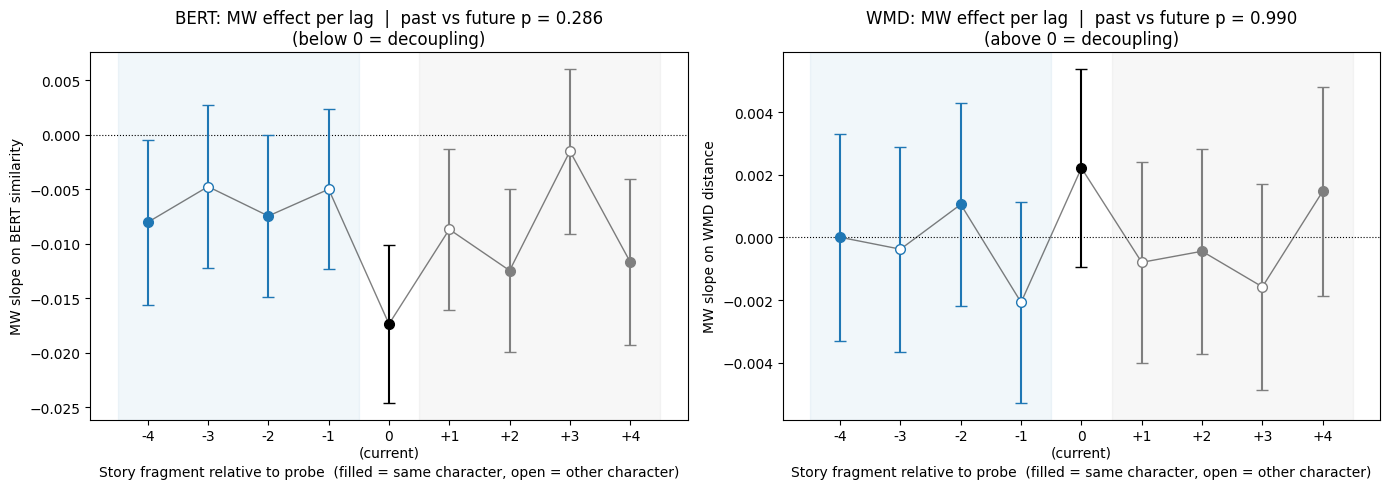

,measure,test,coef,se,z,p,CI_low,CI_high
0,BERT,MW slope at lag -4,-0.008025,0.003863,-2.077388,0.037766,-0.015597,-0.000454
1,BERT,MW slope at lag -3,-0.004753,0.003819,-1.244437,0.213339,-0.012238,0.002733
2,BERT,MW slope at lag -2,-0.007447,0.003775,-1.972987,0.048497,-0.014846,-0.000049
3,BERT,MW slope at lag -1,-0.004994,0.003738,-1.336081,0.181523,-0.012320,0.002332
4,BERT,MW slope at lag +0,-0.017352,0.003684,-4.709725,0.000002,-0.024573,-0.010131
5,BERT,MW slope at lag +1,-0.008670,0.003751,-2.311223,0.020821,-0.016023,-0.001318
6,BERT,MW slope at lag +2,-0.012448,0.003812,-3.265490,0.001093,-0.019919,-0.004976
7,BERT,MW slope at lag +3,-0.001505,0.003851,-0.390913,0.695862,-0.009053,0.006042
8,BERT,MW slope at lag +4,-0.011671,0.003892,-2.998837,0.002710,-0.019299,-0.004043
9,BERT,past vs future,0.002269,0.002125,1.067504,0.285744,-0.001897,0.006434


In [15]:
### (4) Lag analysis – does MW-related decoupling depend on WHICH fragment (past / current / future)?
# Long format: one row = one thought report x one lag. Lag 0 = fragment just heard.
# Lags present in the data (+-2 now, +-4 after re-running storyDataExtraction.py)
MAX_LAG   = 4
lag_order = [l for l in range(-MAX_LAG, MAX_LAG + 1)
             if l == 0 or f"semDecoupling_BERT_{'p' if l < 0 else 'n'}{abs(l)}" in df_Analysis.columns]
lag_map   = {('' if l == 0 else f"{'p' if l < 0 else 'n'}{abs(l)}"): l for l in lag_order}   # column suffix -> lag
lag_lab   = {l: ('L0' if l == 0 else f"L{'m' if l < 0 else 'p'}{abs(l)}") for l in lag_order}  # lag -> category label
print('Lags used:', lag_order)

from analysisFunctions import make_long, contrast, plot_slope_differences, lag_contrasts, omnibus_equal_slopes

def add_contrast_result(m, res, analysisLabel, subLabel, time='trialNum'):
    """Append a slope/contrast result (dict from `contrast`) to the main results table (results.xlsx) and the log.
    The time-on-task columns take `time` from the same lag model."""
    ci = m.conf_int()
    for lst, val in zip((coefs, zvals, pvals, conf1, conf2),
                        (res['coef'], res['z'], res['p'], res['CI_low'], res['CI_high'])):
        lst.append(val)
    for lst, val in zip((coefsT, zvalsT, pvalsT, conf1T, conf2T),
                        (m.params[time], m.tvalues[time], m.pvalues[time], ci.loc[time, 0], ci.loc[time, 1])):
        lst.append(val)
    analysis.append(analysisLabel); subAnalysis.append(subLabel)
    log_file.write(f"\n[{analysisLabel} | {subLabel}]  Coef: {res['coef']:7.4f} | z: {res['z']:7.3f} | p: {res['p']:.4f}\n")
                                                                                                                                                                                                                                                                                                                                                                                                                                                

# Separate MW slope for every lag (no common MW term) -> slopes read directly from params
formula = "sim ~ 0 + C(lag_lab) + C(lag_lab):MW_relative + trialNum + LemmaLen"
sn = lambda l: f"C(lag_lab)[{lag_lab[l]}]:MW_relative"      # name of the MW slope at lag l

measures_lag = [('BERT', 'semDecoupling_BERT'), ('WMD', 'semDecoupling_WMD')]
lag_rows = []

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for i, (label, base) in enumerate(measures_lag):
    long = make_long(df_Analysis, base,lag_lab,lag_map,lag_order)

    # Random intercept + random MW slope per subject; trial as variance component
    # (each thought report enters the data once per lag)
    m = smf.mixedlm(formula, data=long, groups='Subject', re_formula='~MW_relative',
                    vc_formula={'trial': '0 + C(trial_id)'}).fit(method=['lbfgs'])
    print(f"===== LAG MODEL {label} ====="); print(m.summary())

    # Simple MW slopes per lag:  Effects 
    slopes = {l: contrast(m, {sn(l): 1}) for l in lag_order}

    # Planned contrasts on MW slopes (built for the available lags) + omnibus
    tests = lag_contrasts(m, sn, lag_order)
    chi2, p_omni, df_omni = omnibus_equal_slopes(m, sn, lag_order)
    print(f"{label} omnibus (equal MW slopes across lags): chi2({df_omni})={chi2:.3f}, p={p_omni:.4f}")


    ### Specific Tests from our model + saved in separate matrix
    for l, s in slopes.items():
        lag_rows.append({'measure': label, 'test': f"MW slope at lag {l:+d}", **s})
    for name, s in tests.items():
        lag_rows.append({'measure': label, 'test': name, **s})
        print(f"{label} | {name:24s} coef={s['coef']:.4f} z={s['z']:.3f} p={s['p']:.4f}")

    ### Also into the main results table (results.xlsx)
    for l, s in slopes.items():
        add_contrast_result(m, s, "Lag analysis (all)", f"{label} | MW slope at lag {l:+d}")
    for name, s in tests.items():
        add_contrast_result(m, s, "Lag analysis (all)", f"{label} | {name}")
    add_contrast_result(m, {'coef': chi2, 'z': np.nan, 'p': p_omni, 'CI_low': np.nan, 'CI_high': np.nan},
                        "Lag analysis (all)", f"{label} | omnibus equal slopes (chi2 in coef, df={df_omni})")

    # Plot: MW slope (+95% CI) as a function of lag
    plot_slope_differences(slopes, lag_order, label, tests['past vs future']['p'], ax[i])

plt.tight_layout()
plt.savefig(os.path.join(resultsPath, 'lag_analysis.png'), dpi=200)
plt.show()

df_lag = pd.DataFrame(lag_rows)
df_lag.to_excel(os.path.join(resultsPath, 'lag_analysis.xlsx'), index=False)
df_lag


## (6) Is there semantic decoupling from the WHOLE story during higher mind wandering?

Similarity between each thought report and the **rest of the story**: the centroid of all story fragments
**except the current one** (BERT: sentence embeddings, centroid aggregation; WMD: distance to all lemmas of the story).
If MW reduces similarity to the current fragment *and* to the rest of the story, thoughts leave the narrative altogether;
if MW reduces similarity only to the current fragment, thoughts stay within the story.

Model (as in (2)): `Similarity_whole ~ MW_relative + trialNum + LemmaLen + (1 | Subject)`.
In a second step, similarity to the current fragment is added as a covariate: does MW predict similarity to the rest of the story
**beyond** what is explained by similarity to the current fragment?


c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


                Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: semDecoupling_BERT_whole
No. Observations: 686     Method:             REML                    
No. Groups:       18      Scale:              0.0085                  
Min. group size:  26      Log-Likelihood:     610.6712                
Max. group size:  40      Converged:          Yes                     
Mean group size:  38.1                                                
------------------------------------------------------------------------
                    Coef.    Std.Err.     z      P>|z|   [0.025   0.975]
------------------------------------------------------------------------
Intercept            0.408      0.023   17.596   0.000    0.362    0.453
MW_relative         -0.013      0.004   -3.246   0.001   -0.021   -0.005
trialNum             0.000      0.000    0.928   0.353   -0.000    0.001
Pref_relative        0.006      0.004    1.615   0.106   -0.001    0.014
LemmaLen 

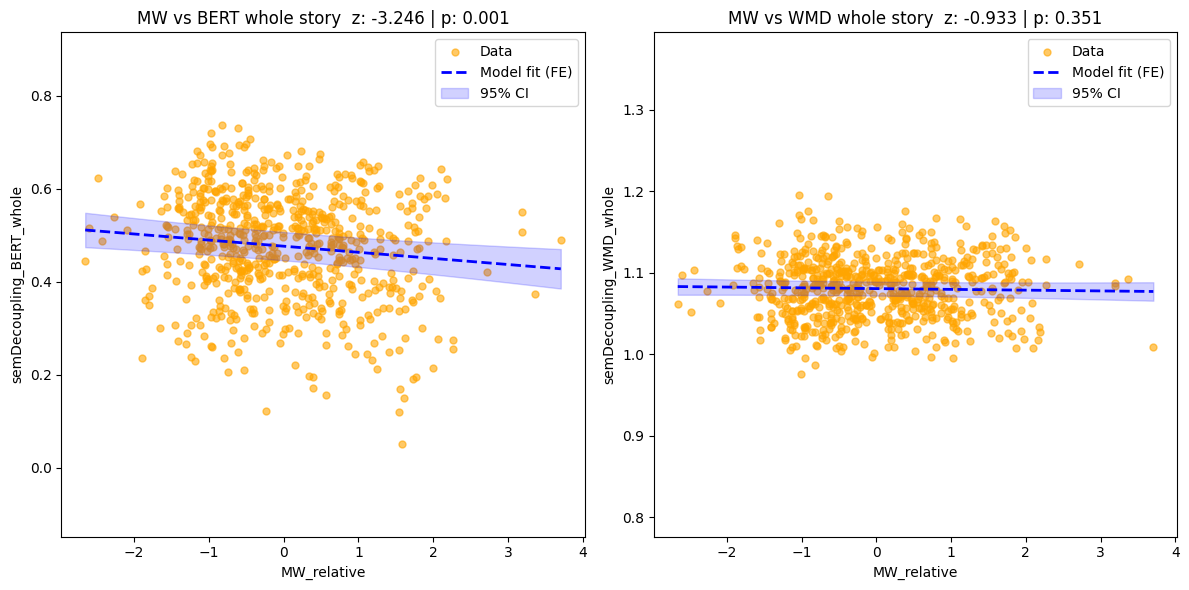

,measure,target,beta_z,z,p,CI_low,CI_high
0,BERT,current fragment,-0.155952,-4.646154,0.000003,-0.221740,-0.090164
1,BERT,whole story,-0.139891,-4.398103,0.000011,-0.202231,-0.077550
2,WMD,current fragment,0.029868,1.004510,0.315133,-0.028409,0.088145
3,WMD,whole story,0.005622,0.230907,0.817387,-0.042098,0.053342


In [16]:
### (2b) Semantic decoupling from the WHOLE story (without the current fragment)
df_current = df_Analysis.dropna(subset=['semDecoupling_BERT_whole', 'semDecoupling_WMD_whole'])

### Models (analogous to (2)):
m_bert_w = smf.mixedlm("semDecoupling_BERT_whole ~ MW_relative + trialNum + Pref_relative+ LemmaLen", data=df_current, groups="Subject").fit()
print(m_bert_w.summary())

m_wmd_w = smf.mixedlm("semDecoupling_WMD_whole ~ MW_relative + trialNum + Pref_relative + LemmaLen", data=df_current, groups="Subject").fit()
print(m_wmd_w.summary())

### Beyond the current fragment: control for similarity to the fragment just heard
m_bert_wc = smf.mixedlm("semDecoupling_BERT_whole ~ MW_relative + semDecoupling_BERT + trialNum + LemmaLen", data=df_current, groups="Subject").fit()
print(m_bert_wc.summary())

m_wmd_wc = smf.mixedlm("semDecoupling_WMD_whole ~ MW_relative + semDecoupling_WMD + trialNum + LemmaLen", data=df_current, groups="Subject").fit()
print(m_wmd_wc.summary())

### Log Results:
log_file.write("\n===# (2b) Semantic Decoupling from the WHOLE story vs MW #===\n")
add_result(m_bert_w,  "MW_relative", "Whole-story decoupling vs MW", "BERT")
add_result(m_wmd_w,   "MW_relative", "Whole-story decoupling vs MW", "WMD")
add_result(m_bert_wc, "MW_relative", "Whole-story decoupling vs MW", "BERT (controlling current fragment)")
add_result(m_wmd_wc,  "MW_relative", "Whole-story decoupling vs MW", "WMD (controlling current fragment)")

### Plot:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
plot_continous_results(m_bert_w, df_current, "MW_relative", "semDecoupling_BERT_whole", ax[0],
    titl=f"MW vs BERT whole story  z: {m_bert_w.tvalues['MW_relative']:.3f} | p: {m_bert_w.pvalues['MW_relative']:.3f}")
plot_continous_results(m_wmd_w, df_current, "MW_relative", "semDecoupling_WMD_whole", ax[1],
    titl=f"MW vs WMD whole story  z: {m_wmd_w.tvalues['MW_relative']:.3f} | p: {m_wmd_w.pvalues['MW_relative']:.3f}")
plt.tight_layout()
plt.savefig(os.path.join(resultsPath, 'whole_story_decoupling.png'), dpi=200, bbox_inches='tight')
plt.show()

### Standardized comparison: MW effect on current fragment vs whole story (slopes in SD units)
comp = []
for label, cur, whole in [('BERT', 'semDecoupling_BERT', 'semDecoupling_BERT_whole'),
                          ('WMD',  'semDecoupling_WMD',  'semDecoupling_WMD_whole')]:
    for name, col in [('current fragment', cur), ('whole story', whole)]:
        d = df_current.assign(y=(df_current[col] - df_current[col].mean()) / df_current[col].std())
        mz = smf.mixedlm("y ~ MW_relative + trialNum + LemmaLen", data=d, groups="Subject").fit()
        ci = mz.conf_int().loc['MW_relative']
        comp.append({'measure': label, 'target': name, 'beta_z': mz.params['MW_relative'],
                     'z': mz.tvalues['MW_relative'], 'p': mz.pvalues['MW_relative'], 'CI_low': ci[0], 'CI_high': ci[1]})
df_whole_comp = pd.DataFrame(comp)
df_whole_comp.to_excel(os.path.join(resultsPath, 'whole_story_vs_current.xlsx'), index=False)
df_whole_comp


## (7) Autobiographical Features

Here we test whether autobiographical features of Particiapnts utterances differ in Attention and Tracked/Not tracked stories

#### Statistical Note:

Since Language, and especially Word Counts are rarely normally disributed we have utilise new procedures
+ We Cannot use Word Count per -person - since we are interested in the intersection of Attention (Where Innatentive and Attentive are not equivalent)
+ We want to test across participants - So we NEED to account for their Variability
+ Linear Mixed Effects or any other traditional Mixed Effects models will likely NOT SUFFICE - they have the same Assumptions as all other linear models: (Homoscedascisity, Residual being normally distributed  - i.e. our dependent variable, co-linearity). Here, we dont have normal distribution - we have to account for that
+ Counts also have a Distribution that is almost Ordinal-like --> We need to account for that
+ Our Autobiographical words come from utterances of varyign length - therefore number alone often than not is not sufficient


In other words, We need a test that can account for different word count, uneven classess, participants variability and non-normal distributions - and of a kind in which our data will not violate assumptions:\


##### GLMS
We decided upon **Clusteting Generalised Linear Mixed Effects with Wordcount Offset**. Generalized Linear Models operate on the assumptions that dependent Y variable has been DRAWN from a given family of Exponential Distributions (Not just normal). More precisely, we try to find E(Y|X) - which by the way is *expected value* as a LINK FUNCTION ^-1 of our X * Beta linear predictors:
![image.png](attachment:image.png)

GLM consists of 3 components:
1. Particular Distribution of Y 
2. Linear predictos X*Beta
3. A LINK FUNCTION g so that we LINK our Y variable with selected distributi

The link function provides the relationship between the linear predictor and the mean of the distribution function. There are many commonly used link functions, and their choice is informed by several considerations. Each Cannonical Distribution has its own Link function to pair. For Poisson and Negative Binomial distributio --> LOG is a selected link function:

So we need to find Log(E(X|Y)) = X*Beta!!! 


##### Our Models 
+ We use GLM --> So a model in which we assume and give a distribution of our residulas to fit: 
+ Our Distibution is **NEGATIVE BINOMIAL**
        +  Classic Poisson Distribution, which accounts to amount of rare occurance is not suitable - because it assumes independence of occurance and more importantly has a hard assumption Var(Y) = E(Y) - and in language, ourt Words are NOT independent and are highly varied - moreso that their expected value
        + In similar fashion the classic BINOMIAL whicha ccounts for the probability of a gicen occuerence is also a wrong fit, because it also does not account for jheavy Zero-skewing: 
    
    It is still not ideal, since we assume indpendence of trials drawing Personal Pronouns from the distribution
        + It handles overdispersion
        + It is well suited to Rare events and sekwed distributions!
+ We add OFFSET: so basically aneducated NORMALISATION by lemmaN - but in a way not to destroy statistical interpretation of Negative Binomial"
    
    *log(E[Y])=Xβ+β2​log(LemmaN)*

    *μi​=exp(Xi​β+log(LemmaNi​))*
+ Lastly we add CLUSTERING: Here, clustering works a tad bit differently than in Linear Mixed Effects modelling: Here, we estiamte normally our model with assumption of Indpendence - this is wrong! We know that our variables COMES from different subjects:
        Clusteitng thus replaces COVARIANCE MATRIX: For that we use "sandwich estimator" - Var(β^​)=A−1BA−1 -- Basically, we Estiamte Variance by getting Fisher model tertm: X^T * W * X  = A AND B - which is a residuals per clusters (In our case per subject) - B=j=1∑J​uj​ujT​

        So instead of assuming - Each trial is Independent WE assume that SUBJECTS are INDEPENDENT - but within the subjects we can have corelated observations 

        Mixed Models explicitluy model UJ - and estiamte VARIANCE components and Changes likeliegood - which LCustetring DOES NOT. it DOES NOT change the parameters - However it allows for testing FOR clustrting inside the subjects!! !


### 7.1 Autobiographical word Count ~ MW Relative

                 Generalized Linear Model Regression Results                  
Dep. Variable:             pPronCount   No. Observations:                  686
Model:                            GLM   Df Residuals:                      682
Model Family:                 Poisson   Df Model:                            3
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -778.69
Date:                Tue, 03 Nov 2026   Deviance:                       742.53
Time:                        09:37:09   Pearson chi2:                     663.
No. Iterations:                     5   Pseudo R-squ. (CS):            0.02142
Covariance Type:              cluster                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept              -3.8597    

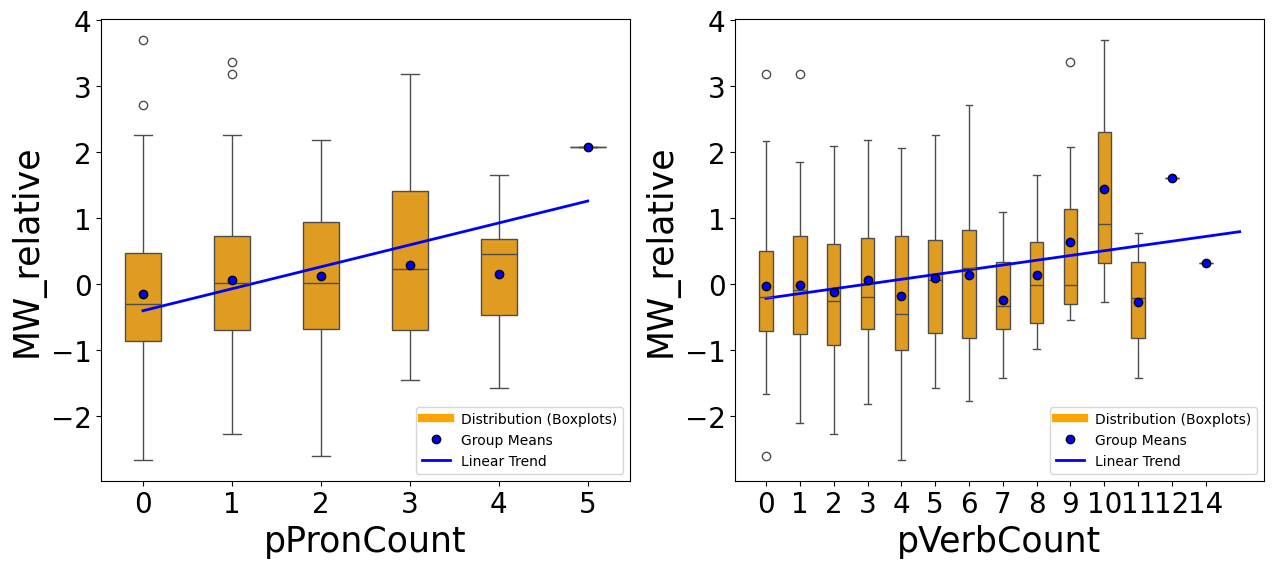

In [17]:
from analysisFunctions import diffRainPlot, linear_boxplot

df_Analysis['PPron_Norm'] = df_Analysis['pPronCount'] / df_Analysis['LemmaLen']
df_Analysis['PVerb_Norm'] = df_Analysis['pVerbCount'] / df_Analysis['LemmaLen']

### (7) Autobiographical features ~ MW
# Fixed-effects Poisson (QMLE): rate of 1st-person words per word, within-subject effect of MW.
# Robust to overdispersion (only the mean must be correct) -> one model for pronouns AND verbs.
df_ab = df_Analysis.copy()
df_ab['nWords']   = df_ab['Utterance'].str.split().str.len()     # ALL words (lemmas exclude pronouns = stop-words)
df_ab['logWords'] = np.log(df_ab['nWords'])
grp = pd.factorize(df_ab['Subject'])[0]

log_file.write("\n===# (7) Autobiographical features #===\n")
ab_models = {}
for dv, lab in [('pPronCount', '1st-person pronouns'), ('pVerbCount', '1st-person verbs')]:
    m = smf.glm(f"{dv} ~ MW_relative + trialNum + recallfirst", data=df_ab,
                family=sm.families.Poisson(), offset=df_ab['logWords']).fit(
                cov_type='cluster', cov_kwds={'groups': grp})
    ab_models[dv] = m
    print(m.summary())
    rr, ci = np.exp(m.params['MW_relative']), np.exp(m.conf_int().loc['MW_relative'])
    print(f"===== {lab} =====\n  RR per 1 SD of MW = {rr:.3f}  [{ci[0]:.3f}, {ci[1]:.3f}],  "
          f"z = {m.tvalues['MW_relative']:.2f},  p = {m.pvalues['MW_relative']:.4f}")
    add_result(m, 'MW_relative', "Autobiographical features", f"{lab} (FE-Poisson)")


fig, ax = plt.subplots(1,2,figsize=(15, 6))
linear_boxplot(df_Analysis, 'pPronCount', 'MW_relative',ax[0], os.path.join(resultsPath,  "pPronCount vs MW_relative.svg"))
linear_boxplot(df_Analysis, 'pVerbCount', 'MW_relative',ax[1], os.path.join(resultsPath,  "pPronCount vs MW_relative.svg"))
fig.savefig(resultsPath, dpi=300, bbox_inches='tight')


### 7.2 Autobiographical word Count ~ Preference

                 Generalized Linear Model Regression Results                  
Dep. Variable:             pPronCount   No. Observations:                  686
Model:                            GLM   Df Residuals:                      682
Model Family:                 Poisson   Df Model:                            3
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -784.28
Date:                Tue, 03 Nov 2026   Deviance:                       753.71
Time:                        09:37:10   Pearson chi2:                     664.
No. Iterations:                     5   Pseudo R-squ. (CS):           0.005344
Covariance Type:              cluster                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept              -3.8927    

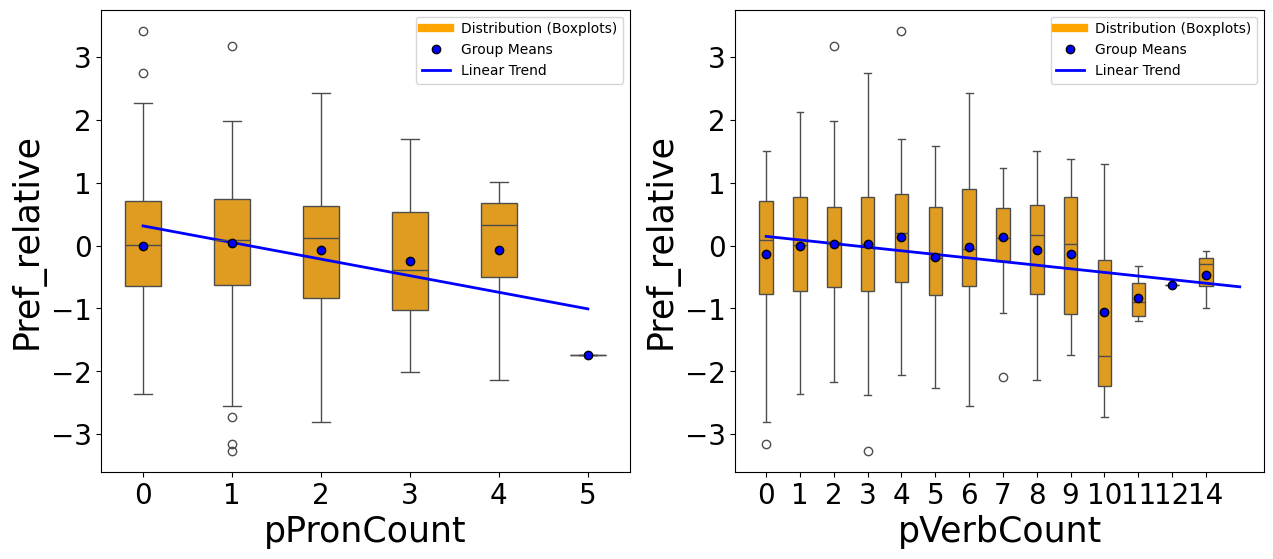

In [18]:
from analysisFunctions import diffRainPlot, linear_boxplot

df_Analysis['PPron_Norm'] = df_Analysis['pPronCount'] / df_Analysis['LemmaLen']
df_Analysis['PVerb_Norm'] = df_Analysis['pVerbCount'] / df_Analysis['LemmaLen']

### (7) Autobiographical features ~ MW
# Fixed-effects Poisson (QMLE): rate of 1st-person words per word, within-subject effect of MW.
# Robust to overdispersion (only the mean must be correct) -> one model for pronouns AND verbs.
df_ab = df_Analysis.copy()
df_ab['nWords']   = df_ab['Utterance'].str.split().str.len()     # ALL words (lemmas exclude pronouns = stop-words)
df_ab['logWords'] = np.log(df_ab['nWords'])
grp = pd.factorize(df_ab['Subject'])[0]

log_file.write("\n===# (7) Autobiographical features #===\n")
ab_models = {}
for dv, lab in [('pPronCount', '1st-person pronouns'), ('pVerbCount', '1st-person verbs')]:
    m = smf.glm(f"{dv} ~ Pref_relative + trialNum + recallfirst", data=df_ab,
                family=sm.families.Poisson(), offset=df_ab['logWords']).fit(
                cov_type='cluster', cov_kwds={'groups': grp})
    ab_models[dv] = m
    print(m.summary())
    rr, ci = np.exp(m.params['Pref_relative']), np.exp(m.conf_int().loc['Pref_relative'])
    print(f"===== {lab} =====\n  RR per 1 SD of MW = {rr:.3f}  [{ci[0]:.3f}, {ci[1]:.3f}],  "
          f"z = {m.tvalues['Pref_relative']:.2f},  p = {m.pvalues['Pref_relative']:.4f}")
    add_result(m, 'Pref_relative', "Autobiographical features Preference", f"{lab} (FE-Poisson)")


fig, ax = plt.subplots(1,2,figsize=(15, 6))
linear_boxplot(df_Analysis, 'pPronCount', 'Pref_relative',ax[0], os.path.join(resultsPath,  "pPronCountVsPref_relative.svg"))
linear_boxplot(df_Analysis, 'pVerbCount', 'Pref_relative',ax[1], os.path.join(resultsPath,  "pVerbCountVsPref_relative.svg"))

### 7.3 Autobiographical word Count ~ Attention

c:\Users\barak\Documents\GitHub\Experiment_MW_Story\analysis\analysisFunctions.py:1946: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\analysis\analysisFunctions.py:1946: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


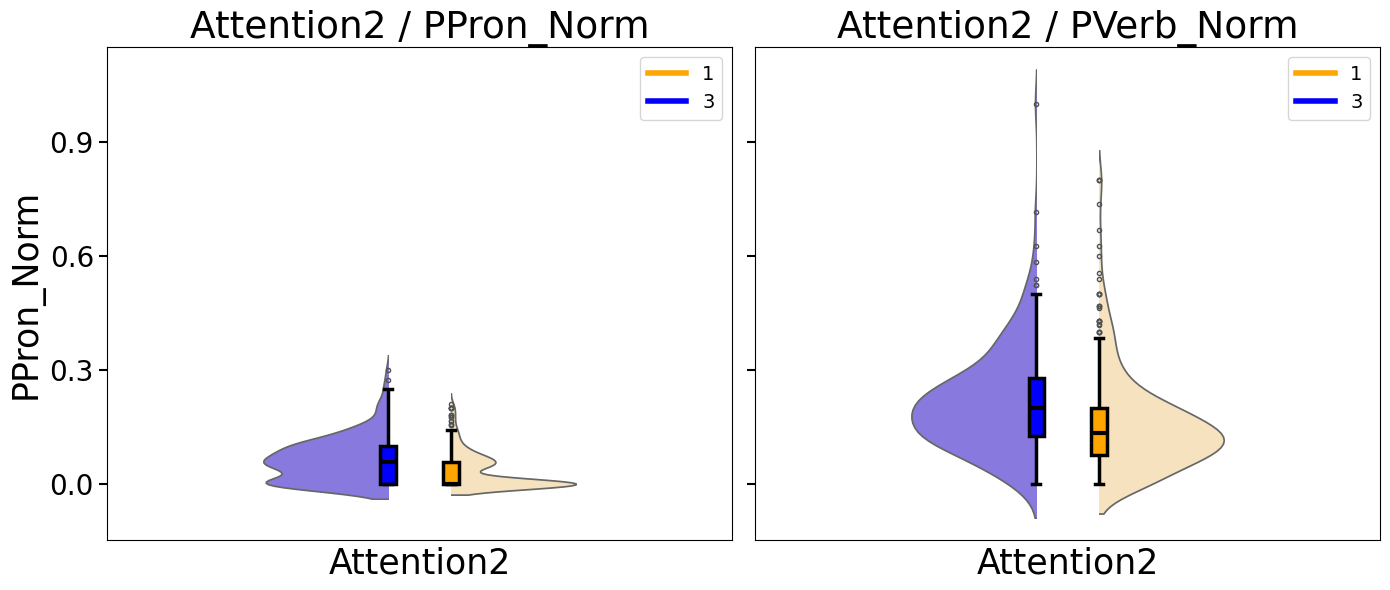

In [19]:
### PLOTS of Personal Pronounx x Attention and Tracking

df_Analysis['PPron_Norm'] = df_Analysis['pPronCount'] / df_Analysis['LemmaLen']
df_Analysis['PVerb_Norm'] = df_Analysis['pVerbCount'] / df_Analysis['LemmaLen']

from analysisFunctions import diffRainPlot, linear_boxplot
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
import matplotlib as mpl
mpl.rcParams['svg.fonttype'] = 'none'
diffRainPlot( df=df_Analysis,  x='Attention2',   y='PPron_Norm',
    ax=axes[0], title='Attention2 / PPron_Norm', gap=-0.2)

diffRainPlot( df=df_Analysis, x='Attention2', y='PVerb_Norm',
    ax=axes[1],title='Attention2 / PVerb_Norm',gap=-0.2)

plt.tight_layout()
plt.savefig(os.path.join(resultsPath,"PPRON_violins.svg"), dpi=300, bbox_inches='tight')

In [20]:
df_Analysis['PPron_Norm'] = df_Analysis['pPronCount'] / df_Analysis['LemmaLen']
df_Analysis['PVerb_Norm'] = df_Analysis['pVerbCount'] / df_Analysis['LemmaLen']

### (7) Autobiographical features ~ MW
# Fixed-effects Poisson (QMLE): rate of 1st-person words per word, within-subject effect of MW.
# Robust to overdispersion (only the mean must be correct) -> one model for pronouns AND verbs.
df_ab = df_Analysis.copy()
df_ab['nWords']   = df_ab['Utterance'].str.split().str.len()     # ALL words (lemmas exclude pronouns = stop-words)
df_ab['logWords'] = np.log(df_ab['nWords'])
grp = pd.factorize(df_ab['Subject'])[0]

log_file.write("\n===# (7) Autobiographical features #===\n")
ab_models = {}
for dv, lab in [('pPronCount', '1st-person pronouns'), ('pVerbCount', '1st-person verbs')]:
    m = smf.glm(f"{dv} ~ MW_relative*Pref_relative + trialNum + recallfirst", data=df_ab,
                family=sm.families.Poisson(), offset=df_ab['logWords']).fit(
                cov_type='cluster', cov_kwds={'groups': grp})
    ab_models[dv] = m
    print(m.summary())
    rr, ci = np.exp(m.params['MW_relative']), np.exp(m.conf_int().loc['MW_relative'])
    print(f"===== {lab} =====\n  RR per 1 SD of MW = {rr:.3f}  [{ci[0]:.3f}, {ci[1]:.3f}],  "
          f"z = {m.tvalues['MW_relative']:.2f},  p = {m.pvalues['MW_relative']:.4f}")
    add_result(m, 'MW_relative', "Autobiographical features mixed", f"{lab} (FE-Poisson)")


                 Generalized Linear Model Regression Results                  
Dep. Variable:             pPronCount   No. Observations:                  686
Model:                            GLM   Df Residuals:                      680
Model Family:                 Poisson   Df Model:                            5
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -777.21
Date:                Tue, 03 Nov 2026   Deviance:                       739.58
Time:                        09:37:10   Pearson chi2:                     658.
No. Iterations:                     5   Pseudo R-squ. (CS):            0.02562
Covariance Type:              cluster                                         
                                coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------
Intercept             

In [37]:
df_Analysis['LemmaLen'] = [len(i) for i in df_Analysis['Lemmas'].apply(ast.literal_eval)]


df_Analysis['PPron_Norm'] = df_Analysis['pPronCount'] / df_Analysis['LemmaLen']
df_Analysis['PVerb_Norm'] = df_Analysis['pVerbCount'] / df_Analysis['LemmaLen']

### (7) Autobiographical features ~ MW
# Fixed-effects Poisson (QMLE): rate of 1st-person words per word, within-subject effect of MW.
# Robust to overdispersion (only the mean must be correct) -> one model for pronouns AND verbs.
df_ab = df_Analysis.copy()
df_ab['nWords']   = df_ab['Utterance'].str.split().str.len()     # ALL words (lemmas exclude pronouns = stop-words)
df_ab['logWords'] = np.log(df_ab['nWords'])
grp = pd.factorize(df_ab['Subject'])[0]

log_file.write("\n===# (7) Autobiographical features #===\n")
ab_models = {}
for dv, lab in [('pPronCount', '1st-person pronouns'), ('pVerbCount', '1st-person verbs')]:
    m = smf.glm(f"{dv} ~ Pref_relative + trialNum + recallfirst", data=df_ab,
                family=sm.families.Poisson(), offset=df_ab['logWords']).fit(
                cov_type='cluster', cov_kwds={'groups': grp})
    ab_models[dv] = m
    print(m.summary())
    rr, ci = np.exp(m.params['Pref_relative']), np.exp(m.conf_int().loc['Pref_relative'])
    print(f"===== {lab} =====\n  RR per 1 SD of MW = {rr:.3f}  [{ci[0]:.3f}, {ci[1]:.3f}],  "
          f"z = {m.tvalues['Pref_relative']:.2f},  p = {m.pvalues['Pref_relative']:.4f}")
   # add_result(m, 'MW_relative', "Autobiographical features mixed", f"{lab} (FE-Poisson)")


                 Generalized Linear Model Regression Results                  
Dep. Variable:             pPronCount   No. Observations:                  686
Model:                            GLM   Df Residuals:                      682
Model Family:                 Poisson   Df Model:                            3
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -784.28
Date:                Tue, 03 Nov 2026   Deviance:                       753.71
Time:                        09:59:00   Pearson chi2:                     664.
No. Iterations:                     5   Pseudo R-squ. (CS):           0.005344
Covariance Type:              cluster                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept              -3.8927    

## 8. Interoceptive feelings

In [21]:
df_Analysis.describe()

,utteranceLength,Is_semantic_ref,Is_experiment_ref,Is_Introceptive,IS_Wholy_About_Attention,Has_explicit_attention,SentencesLen,LemmasLen,VerbsLen,NounsLen,...,semDecoupling_W2V_p4_c,semDecoupling_W2V_p3_c,semDecoupling_W2V_p2_c,semDecoupling_W2V_p1_c,semDecoupling_W2V_n1_c,semDecoupling_W2V_n2_c,semDecoupling_W2V_n3_c,semDecoupling_W2V_n4_c,PPron_Norm,PVerb_Norm
count,686.000000,686.000000,686.000000,686.000000,686.000000,686.000000,686.000000,686.000000,686.000000,686.000000,...,6.140000e+02,6.320000e+02,6.500000e+02,6.680000e+02,6.700000e+02,6.540000e+02,6.380000e+02,6.220000e+02,686.000000,686.000000
mean,245.950437,0.204082,0.088921,0.097668,0.087464,0.256560,2.255102,18.244898,6.969388,6.709913,...,1.898590e-18,2.547189e-18,1.195625e-18,-5.817037e-19,-1.077082e-18,4.838128e-18,1.914178e-18,-3.391357e-18,0.044759,0.179267
std,76.944480,0.403323,0.284838,0.297081,0.282719,0.552163,1.308232,5.921488,2.849089,3.229714,...,3.078319e-02,3.050056e-02,3.009873e-02,3.110933e-02,3.130694e-02,3.151962e-02,3.101207e-02,2.985994e-02,0.054123,0.135363
min,51.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,5.000000,1.000000,0.000000,...,-8.803103e-02,-9.962850e-02,-1.030045e-01,-8.856364e-02,-1.004446e-01,-1.011107e-01,-8.674994e-02,-8.764792e-02,0.000000,0.000000
25%,196.250000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,14.000000,5.000000,4.000000,...,-2.037578e-02,-2.185948e-02,-1.934760e-02,-2.019959e-02,-1.993503e-02,-1.961034e-02,-2.135416e-02,-2.001986e-02,0.000000,0.090909
50%,252.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,18.000000,7.000000,6.000000,...,-5.841550e-04,-4.655848e-04,4.035401e-04,7.955298e-04,1.821353e-03,-8.000261e-04,1.961654e-03,-8.804811e-04,0.037037,0.150000
75%,298.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000,22.000000,9.000000,9.000000,...,1.872353e-02,2.031653e-02,2.072836e-02,2.120042e-02,2.007406e-02,1.898779e-02,1.938693e-02,2.014203e-02,0.074074,0.230769
max,430.000000,1.000000,1.000000,1.000000,1.000000,4.000000,8.000000,34.000000,19.000000,17.000000,...,1.093769e-01,1.055348e-01,1.025089e-01,1.250567e-01,1.094401e-01,1.158211e-01,1.387869e-01,1.234775e-01,0.300000,1.000000


In [22]:
print(df_Analysis[['Is_experiment_ref']].value_counts())
print(df_Analysis[['Is_Introceptive']].value_counts())
print(df_Analysis[['Is_semantic_ref']].value_counts())

Is_experiment_ref
0                    625
1                     61
Name: count, dtype: int64
Is_Introceptive
0                  619
1                   67
Name: count, dtype: int64
Is_semantic_ref
0                  546
1                  140
Name: count, dtype: int64


                      Mixed Linear Model Regression Results
Model:                    MixedLM         Dependent Variable:         MW_relative
No. Observations:         686             Method:                     REML       
No. Groups:               18              Scale:                      0.9388     
Min. group size:          26              Log-Likelihood:             -958.5779  
Max. group size:          40              Converged:                  Yes        
Mean group size:          38.1                                                   
---------------------------------------------------------------------------------
                                       Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------------------------------
Intercept                               0.037    0.137  0.269 0.788 -0.232  0.306
C(Is_Introceptive)[T.No interoception] -0.440    0.124 -3.543 0.000 -0.683 -0.196
trialNum                              

c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
c:\Users\barak\Documents\GitHub\Experiment_MW_St

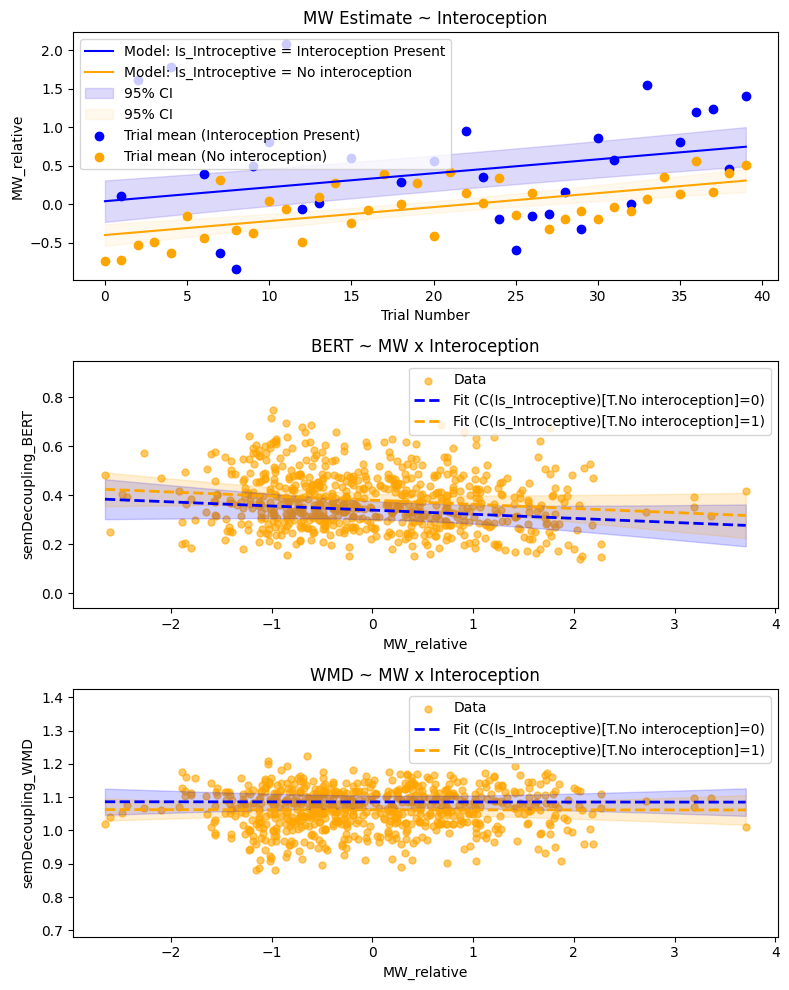

In [23]:
df_current = df_Analysis.copy()
df_current['Is_Introceptive'] = df_current['Is_Introceptive'].map({0: 'No interoception', 1: 'Interoception Present'})

m_int_b = smf.mixedlm("MW_relative ~ C(Is_Introceptive) + trialNum", data=df_current, groups="Subject").fit()
m_int_T = smf.mixedlm("MW_relative ~ C(Is_Introceptive) * Pref_relative + trialNum", data=df_current, groups="Subject").fit()
m_int_SS1 = smf.mixedlm("semDecoupling_BERT ~ MW_relative * C(Is_Introceptive) + trialNum + LemmaLen", data=df_current, groups="Subject").fit()
m_int_SS2 = smf.mixedlm("semDecoupling_WMD ~ MW_relative * C(Is_Introceptive) + trialNum + LemmaLen", data=df_current, groups="Subject").fit()


print(m_int_b.summary()); print(m_int_T.summary()); print(m_int_SS1.summary()); print(m_int_SS2.summary())
add_result(m_int_b, "C(Is_Introceptive)[T.No interoception]", "MW vs Interoception", "MW ~ Interoception")
add_result(m_int_T, "C(Is_Introceptive)[T.No interoception]", "MW vs Interoception", "MW ~ Interoception main effect")
add_result(m_int_T, "C(Is_Introceptive)[T.No interoception]:Pref_relative", "MW vs Interoception", "MW ~ Interoception x Tracking")
add_result(m_int_SS1, "C(Is_Introceptive)[T.No interoception]", "BERT vs Interoception", "BERT ~ Interoception main effect")
add_result(m_int_SS1, "MW_relative:C(Is_Introceptive)[T.No interoception]", "BERT vs Interoception", "BERT ~ MW x Interoception")
add_result(m_int_SS2, "C(Is_Introceptive)[T.No interoception]", "WMD vs Interoception", "WMD ~ Interoception main effect")
add_result(m_int_SS2, "MW_relative:C(Is_Introceptive)[T.No interoception]", "WMD vs Interoception", "WMD ~ MW x Interoception")

fig, ax = plt.subplots(3, 1, figsize=(8, 10))
plotTrialTrack(m_int_b, 'MW_relative', df_current, ax[0], titl='MW Estimate ~ Interoception', anlysisName='Is_Introceptive', firstContrast='Interoception Present', lastContrast='No interoception')
plot_continous_results(m_int_SS1, df_current, "MW_relative", "semDecoupling_BERT", ax[1], titl='BERT ~ MW x Interoception', group_param="C(Is_Introceptive)[T.No interoception]")
plot_continous_results(m_int_SS2, df_current, "MW_relative", "semDecoupling_WMD", ax[2], titl='WMD ~ MW x Interoception', group_param="C(Is_Introceptive)[T.No interoception]")
plt.tight_layout()
plt.savefig(os.path.join(resultsPath, 'Interoceptive.png'), dpi=200)


c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
c:\Users\barak\Documents\GitHub\Experiment_MW_St

                       Mixed Linear Model Regression Results
Model:                     MixedLM          Dependent Variable:          MW_relative
No. Observations:          686              Method:                      REML       
No. Groups:                18               Scale:                       0.9494     
Min. group size:           26               Log-Likelihood:              -962.3635  
Max. group size:           40               Converged:                   Yes        
Mean group size:           38.1                                                     
------------------------------------------------------------------------------------
                                          Coef.  Std.Err.   z    P>|z| [0.025 0.975]
------------------------------------------------------------------------------------
Intercept                                 -0.108    0.145 -0.750 0.453 -0.392  0.175
C(Is_experiment_ref)[T.No Experiment Ref] -0.282    0.131 -2.156 0.031 -0.538 -0.026
tria

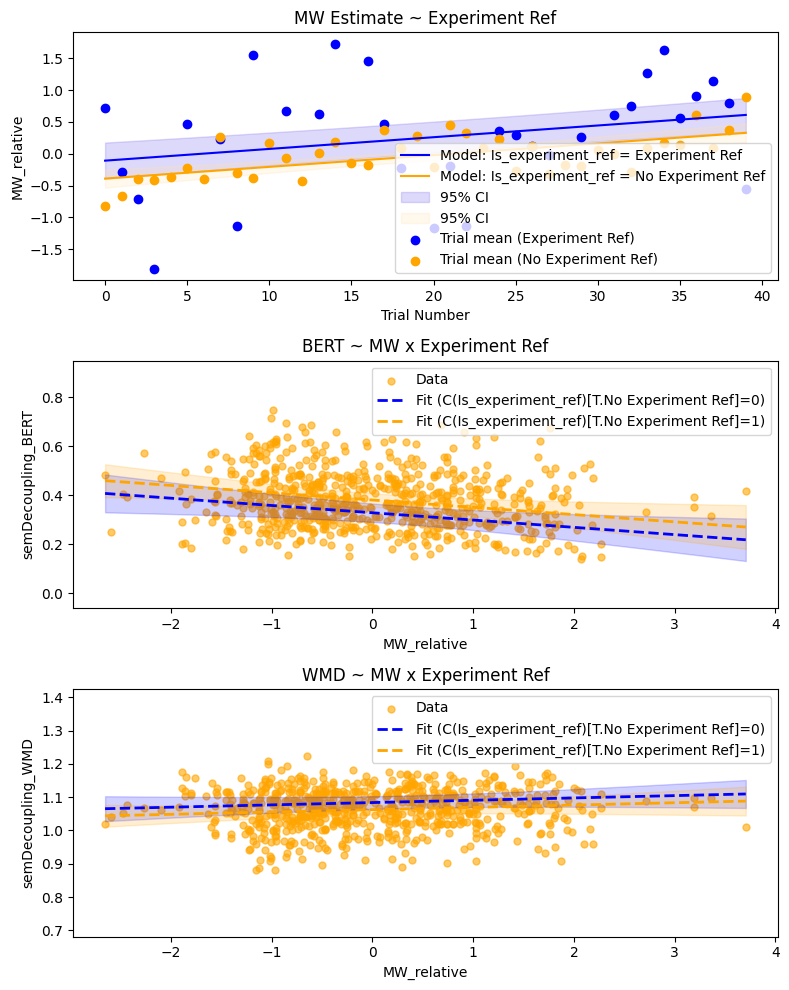

In [24]:
### MW vs Experiment Ref
df_current = df_Analysis.copy()
df_current['Is_experiment_ref'] = df_current['Is_experiment_ref'].map({0: 'No Experiment Ref', 1: 'Experiment Ref'})

m_int_b = smf.mixedlm("MW_relative ~ C(Is_experiment_ref) + trialNum", data=df_current, groups="Subject").fit()
m_int_T = smf.mixedlm("MW_relative ~ C(Is_experiment_ref) * Pref_relative + trialNum", data=df_current, groups="Subject").fit()
m_int_SS1 = smf.mixedlm("semDecoupling_BERT ~ MW_relative * C(Is_experiment_ref) + trialNum + LemmaLen", data=df_current, groups="Subject").fit()
m_int_SS2 = smf.mixedlm("semDecoupling_WMD ~ MW_relative * C(Is_experiment_ref) + trialNum + LemmaLen", data=df_current, groups="Subject").fit()
print(m_int_b.summary()); print(m_int_T.summary()); print(m_int_SS1.summary()); print(m_int_SS2.summary())

add_result(m_int_b, "C(Is_experiment_ref)[T.No Experiment Ref]", "MW vs Story Experiment Ref", "MW ~ Interoception")
add_result(m_int_T, "C(Is_experiment_ref)[T.No Experiment Ref]", "MW vs Story Experiment Ref", "MW ~ Interoception main effect")
add_result(m_int_T, "C(Is_experiment_ref)[T.No Experiment Ref]:Pref_relative", "MW vs Story Experiment Ref", "MW ~ Interoception x Tracking")
add_result(m_int_SS1, "C(Is_experiment_ref)[T.No Experiment Ref]", "MW vs Story Experiment Ref", "BERT ~ Interoception main effect")
add_result(m_int_SS1, "MW_relative:C(Is_experiment_ref)[T.No Experiment Ref]", "MW vs Story Experiment Ref", "BERT ~ MW x Interoception")
add_result(m_int_SS2, "C(Is_experiment_ref)[T.No Experiment Ref]", "MW vs Story Experiment Ref", "WMD ~ Interoception main effect")
add_result(m_int_SS2, "MW_relative:C(Is_experiment_ref)[T.No Experiment Ref]", "MW vs Story Experiment Ref", "WMD ~ MW x Interoception")

fig, ax = plt.subplots(3, 1, figsize=(8, 10))
plotTrialTrack(m_int_b, 'MW_relative', df_current, ax[0], titl='MW Estimate ~ Experiment Ref', anlysisName='Is_experiment_ref', firstContrast='Experiment Ref', lastContrast='No Experiment Ref')
plot_continous_results(m_int_SS1, df_current, "MW_relative", "semDecoupling_BERT", ax[1], titl='BERT ~ MW x Experiment Ref', group_param="C(Is_experiment_ref)[T.No Experiment Ref]")
plot_continous_results(m_int_SS2, df_current, "MW_relative", "semDecoupling_WMD", ax[2], titl='WMD ~ MW x Experiment Ref', group_param="C(Is_experiment_ref)[T.No Experiment Ref]")
plt.tight_layout()
plt.savefig(os.path.join(resultsPath, 'Experimtent_Thoughts.png'), dpi=200)


In [ ]:
df_current = df_Analysis.copy()
df_current['Is_semantic_ref'] = df_current['Is_semantic_ref'].map({0: 'No Pondering', 1: 'Pondering'})

m_int_b = smf.mixedlm("MW_relative ~ C(Is_semantic_ref) + trialNum", data=df_current, groups="Subject").fit()
m_int_T = smf.mixedlm("MW_relative ~ C(Is_semantic_ref) * Pref_relative + trialNum", data=df_current, groups="Subject").fit()
m_int_SS1 = smf.mixedlm("semDecoupling_BERT ~ MW_relative * C(Is_semantic_ref) + trialNum + LemmaLen", data=df_current, groups="Subject").fit()
m_int_SS2 = smf.mixedlm("semDecoupling_WMD ~ MW_relative * C(Is_semantic_ref) + trialNum + LemmaLen", data=df_current, groups="Subject").fit()
print(m_int_b.summary()); print(m_int_T.summary()); print(m_int_SS1.summary()); print(m_int_SS2.summary())

add_result(m_int_b, "C(Is_semantic_ref)[T.Pondering]", "MW vs Story Pondering", "MW ~ Interoception")
add_result(m_int_T, "C(Is_semantic_ref)[T.Pondering]", "MW vs Story Pondering", "MW ~ Interoception main effect")
add_result(m_int_T, "C(Is_semantic_ref)[T.Pondering]:Pref_relative", "MW vs Story Pondering", "MW ~ Interoception x Pref_relative")
add_result(m_int_SS1, "C(Is_semantic_ref)[T.Pondering]", "MW vs Story Pondering", "BERT ~ Interoception main effect")
add_result(m_int_SS1, "MW_relative:C(Is_semantic_ref)[T.Pondering]", "MW vs Story Pondering", "BERT ~ MW x Interoception")
add_result(m_int_SS2, "C(Is_semantic_ref)[T.Pondering]", "MW vs Story Pondering", "WMD ~ Interoception main effect")
add_result(m_int_SS2, "MW_relative:C(Is_semantic_ref)[T.Pondering]", "MW vs Story Pondering", "WMD ~ MW x Interoception")

fig, ax = plt.subplots(3, 1, figsize=(8, 10))
plotTrialTrack(m_int_b, 'MW_relative', df_current, ax[0], titl='MW Estimate ~ Pondering', anlysisName='Is_semantic_ref', firstContrast='Pondering', lastContrast='No Pondering')
plot_continous_results(m_int_SS1, df_current, "MW_relative", "semDecoupling_BERT", ax[1], titl='BERT ~ MW x Pondering', group_param="C(Is_semantic_ref)[T.Pondering]")
plot_continous_results(m_int_SS2, df_current, "MW_relative", "semDecoupling_WMD", ax[2], titl='WMD ~ MW x Pondering', group_param="C(Is_semantic_ref)[T.Pondering]")
plt.tight_layout()
plt.savefig(os.path.join(resultsPath, 'Pondering.png'), dpi=200)


                  Mixed Linear Model Regression Results
Model:                   MixedLM      Dependent Variable:      MW_relative
No. Observations:        686          Method:                  REML       
No. Groups:              18           Scale:                   0.9498     
Min. group size:         26           Log-Likelihood:          -962.8778  
Max. group size:         40           Converged:               Yes        
Mean group size:         38.1                                             
--------------------------------------------------------------------------
                                Coef.  Std.Err.   z    P>|z| [0.025 0.975]
--------------------------------------------------------------------------
Intercept                       -0.356    0.073 -4.871 0.000 -0.499 -0.213
C(Is_semantic_ref)[T.Pondering] -0.192    0.093 -2.063 0.039 -0.374 -0.010
trialNum                         0.020    0.003  6.113 0.000  0.014  0.026
Subject Var                      0.000      

c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)
c:\Users\barak\Documents\GitHub\Experiment_MW_Story\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
c:\Users\barak\Documents\GitHub\Experiment_MW_St

ValueError: I/O operation on closed file.

### 8.4:

Does Autobiographical Thoughts; Experiment; And Story Reference are more numerous in heightened Preference?

                               GEE Regression Results                              
Dep. Variable:             Is_semantic_ref   No. Observations:                  686
Model:                                 GEE   No. clusters:                       18
Method:                        Generalized   Min. cluster size:                  26
                      Estimating Equations   Max. cluster size:                  40
Family:                           Binomial   Mean cluster size:                38.1
Dependence structure:         Exchangeable   Num. iterations:                     7
Date:                     Tue, 03 Nov 2026   Scale:                           1.000
Covariance type:                    robust   Time:                         10:15:04
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        -1.9833      0.243     -8.177      0.000      -2.459      -1.50

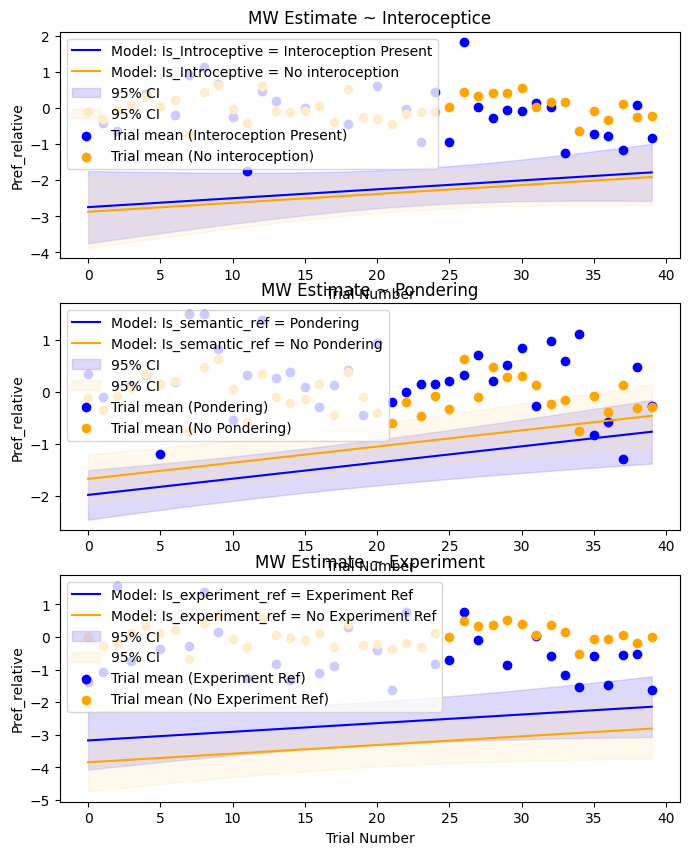

In [40]:
df_current = df_Analysis.copy()
df_current['Is_experiment_ref'] = df_current['Is_experiment_ref'].map({0: 'No Experiment Ref', 1: 'Experiment Ref'})
df_current['Is_Introceptive'] = df_current['Is_Introceptive'].map({0: 'No interoception', 1: 'Interoception Present'})
df_current['Is_semantic_ref'] = df_current['Is_semantic_ref'].map({0: 'No Pondering', 1: 'Pondering'})


m_int_b = smf.gee("Is_semantic_ref ~ Pref_relative + trialNum", groups="Subject", data=df_Analysis,
            family=sm.families.Binomial(), cov_struct=sm.cov_struct.Exchangeable()).fit()
m_int_a = smf.gee("Is_Introceptive ~ Pref_relative + trialNum", groups="Subject", data=df_Analysis,
            family=sm.families.Binomial(), cov_struct=sm.cov_struct.Exchangeable()).fit()
m_int_c = smf.gee("Is_experiment_ref ~ Pref_relative + trialNum", groups="Subject", data=df_Analysis,
            family=sm.families.Binomial(), cov_struct=sm.cov_struct.Exchangeable()).fit()

print(m_int_b.summary()); print(m_int_c.summary()); print(m_int_a.summary())



add_result(m_int_a, "Pref_relative", "Pref_relative vs Text Labels", "Pref_relative ~ Interoceptive")
add_result(m_int_b, "Pref_relative", "Pref_relative vs Text Labels", "Pref_relative ~ Pondering")
add_result(m_int_c, "Pref_relative", "Pref_relative vs Text Labels", "Pref_relative ~ Experiment")


fig, ax = plt.subplots(3, 1, figsize=(8, 10))
plotTrialTrack(m_int_a, 'Pref_relative', df_current, ax[0], titl='MW Estimate ~ Interoceptice', anlysisName='Is_Introceptive', firstContrast='Interoception Present', lastContrast='No interoception')
plotTrialTrack(m_int_b, 'Pref_relative', df_current, ax[1], titl='MW Estimate ~ Pondering', anlysisName='Is_semantic_ref', firstContrast='Pondering', lastContrast='No Pondering')
plotTrialTrack(m_int_c, 'Pref_relative', df_current, ax[2], titl='MW Estimate ~ Experiment', anlysisName='Is_experiment_ref', firstContrast='Experiment Ref', lastContrast='No Experiment Ref')


# Saving all results

All effects are collected by `add_result()` (by parameter name) and saved to `results.xlsx`;
p < .05 in bold (uncorrected). Full model formulas are in `finalStatLog_Behav.txt`.

In [26]:
cols = pd.MultiIndex.from_product(
    [['Main Analysis', 'Time on task'],
     ['coef', 'z', 'p', 'CI_low', 'CI_high']]
)

df = pd.DataFrame(
    list(zip(
        coefs, zvals, pvals, conf1, conf2,
        coefsT, zvalsT, pvalsT, conf1T, conf2T
    )),
    index=pd.MultiIndex.from_arrays(
        [analysis, subAnalysis],
        names=['analysis', 'subAnalysis']
    ),
    columns=cols
)


#### === SAVE === ###
import pandas as pd
from openpyxl import load_workbook
from openpyxl.styles import Font

# --- your df already exists as `df` ---
# Example: save file path
out_path = os.path.join(resultsPath,'results.xlsx')

# Write DataFrame to Excel (pandas will write MultiIndex columns/rows neatly)
df.to_excel(out_path, merge_cells=True)  # merge_cells keeps MultiIndex header nicer

# Re-open the workbook with openpyxl to apply formatting
wb = load_workbook(out_path)
ws = wb.active  # sheet with the DataFrame

bold_font = Font(bold=True)

# Identify header layout:
# By default pandas writes row index labels starting at column A.
# The number of rows used for the column MultiIndex = df.columns.nlevels
col_header_rows = df.columns.nlevels
# The number of index levels (row MultiIndex) determines how many left-most columns are used for the index
index_levels = df.index.nlevels

# Helper: convert 0-based (row, col) to openpyxl 1-based coordinates.
# We need to find which Excel columns correspond to each DataFrame column.
# Pandas places the DataFrame column headers in the first col_header_rows rows,
# and the actual data starts at Excel row = col_header_rows + 1
# The first data column in Excel is column number index_levels + 1 (1-based).
start_col = index_levels + 1  # 1-based excel column index of the first data column
start_row = col_header_rows + 1  # where first data row begins in Excel


# Build a list of the DataFrame's top-level column labels and sub-levels,
# and map them to Excel column indices.
# Flatten df.columns to get (col_index, col_label_tuple)
excel_col = start_col
col_map = {}  # map from (col_tuple) -> excel column number (1-based)
for col in df.columns:
    # col is a tuple when MultiIndex; if single level it's a scalar
    if isinstance(col, tuple):
        col_map[col] = excel_col
    else:
        col_map[(col,)] = excel_col
    excel_col += 1

# Now find all columns where the last level (typically) equals 'p'
# Depending on your MultiIndex structure, you may need to check which level has the name 'p'.
# Here we check any column tuple where any level equals 'p' OR the last level == 'p'.
p_columns = []
for col in df.columns:
    # unify to tuple
    col_t = col if isinstance(col, tuple) else (col,)
    if any(str(level) == 'p' for level in col_t) or (str(col_t[-1]) == 'p'):
        p_columns.append(col_t)

# Iterate over rows of data and apply bold to p-values < 0.05
for row_idx, idx in enumerate(df.index, start=start_row):
    for col_t in p_columns:
        col_num = col_map.get(col_t)
        if col_num is None:
            # sometimes mapping keys differ in tuple shape; try to match by suffix
            # try to find a key in col_map with same length and same values
            for k in list(col_map.keys()):
                if tuple(k) == tuple(col_t):
                    col_num = col_map[k]
                    break
            if col_num is None:
                # try match by last element == 'p'
                for k in list(col_map.keys()):
                    if str(k[-1]) == 'p':
                        col_num = col_map[k]
                        break
                if col_num is None:
                    continue

        cell = ws.cell(row=row_idx, column=col_num)
        # read numeric value (openpyxl reads the written number as number)
        try:
            val = cell.value
            # If pandas wrote scientific notation as string, convert:
            if isinstance(val, str):
                # attempt float conversion
                try:
                    val = float(val)
                except Exception:
                    val = None
            if val is not None and isinstance(val, (int, float)) and val < 0.05:
                cell.font = bold_font
        except Exception:
            # ignore conversion errors
            pass

wb.save(out_path)
print(f"Saved {out_path} with p-values < 0.05 in bold.")
log_file.close()

Saved c:\Users\barak\Documents\GitHub\Experiment_MW_Story\analysis\Results\Main_Analysis\results.xlsx with p-values < 0.05 in bold.
